# Standard ML Training (cyber-attacks-dataset)

**Goal:** Train classical ML classifiers (Logistic Regression, Random Forest, XGBoost) across multiple data splitting strategies to establish performance baselines.

**Input:** Prepared data from `01_data_preparation.ipynb` (saved in `prepared_data/`).
**Key feature:** ML dataset is used for standard ML training; TL dataset is used for temporal/graph-aware splits since it contains IP/timestamp columns.

The day-based splits of the CIC-IDS2017 notebook are mapped onto this dataset's captures:

| Section | CIC-IDS2017 notebooks | cyber-attacks-dataset |
|---|---|---|
| Temporal split | Mon–Thu train / Friday test | **Cross-capture**: train on capture 07, test on capture 10 |
| Day-stratified 70/30 | per day | per capture |
| Chronological 70/15/15 | per day | per capture |
| Per-label chronological 70/15/15 | flow timestamp | `bidirectional_first_seen_ms` |

**Hardware:** Logistic Regression and Random Forest run on the GPU with cuML when it is installed (Linux/WSL with a large GPU), otherwise on the CPU with scikit-learn. XGBoost uses the CUDA GPU when one works and falls back to the CPU otherwise (also when the GPU runs out of memory).

## Configuration

All configurable settings for this notebook. Edit values before running.

In [1]:
from pydantic import BaseModel, Field
from typing import List, Optional


class MLDataConfig(BaseModel):
    """Data loading settings."""
    prepared_data_dir: str = Field(default="prepared_data", description="Directory with prepared data")
    use_ml_dataset: bool = Field(default=True, description="True = ML dataset for random splits, False = TL dataset for all")
    use_correlation_features: bool = Field(default=True, description="Use correlation-selected feature subset")


class ModelHyperparamsConfig(BaseModel):
    """Hyperparameters for all models."""
    lr_max_iter: int = Field(default=1000, description="Logistic Regression max iterations")
    rf_n_estimators: int = Field(default=200, description="Random Forest number of trees")
    rf_max_depth: int = Field(default=16, description="Random Forest max depth")
    xgb_n_estimators: int = Field(default=200, description="XGBoost number of trees (standard sections)")
    xgb_n_estimators_es: int = Field(default=500, description="XGBoost max trees when early stopping is used")
    xgb_max_depth: int = Field(default=6, description="XGBoost max depth")
    xgb_learning_rate: float = Field(default=0.1, description="XGBoost learning rate")
    xgb_early_stopping_rounds: int = Field(default=20, description="XGBoost early stopping patience")
    xgb_device: str = Field(default="auto", description="'auto' (CUDA if it works, else CPU), 'cuda' or 'cpu'")
    run_models: List[str] = Field(default=["Logistic Regression", "Random Forest", "XGBoost"],
                                  description="Models to train (CPU Logistic Regression is by far the slowest)")


class SplitConfig(BaseModel):
    """Train/test split settings."""
    test_size: float = Field(default=0.3, description="Test set proportion for random splits")
    random_state: int = Field(default=42, description="Random seed for reproducibility")
    min_class_samples: int = Field(default=10, description="Multi-class: leave out classes with fewer flows (stratified splitting needs several per class)")


class TimeSplitConfig(BaseModel):
    """Capture-based splits (replace the CIC-IDS2017 day-based splits)."""
    train_captures: List[str] = Field(default=["07"], description="Cross-capture split: training captures")
    test_captures: List[str] = Field(default=["10"], description="Cross-capture split: test captures")


class SectionsConfig(BaseModel):
    """Toggle which experiment sections to run."""
    run_multiclass: bool = Field(default=True, description="Multi-class (target chosen in 01: technique or attack name)")
    run_binary: bool = Field(default=True, description="Binary (BENIGN vs ATTACK)")
    run_balanced: bool = Field(default=True, description="Balanced binary (50/50)")
    run_cross_capture: bool = Field(default=True, description="Cross-capture split (train/test captures)")
    run_capture_stratified: bool = Field(default=True, description="Capture-stratified 70/30")
    run_chronological: bool = Field(default=True, description="Chronological 70/15/15 per capture")
    run_label_stratified: bool = Field(default=True, description="Per-label chronological 70/15/15")


data_cfg = MLDataConfig()
model_cfg = ModelHyperparamsConfig()
split_cfg = SplitConfig()
time_cfg = TimeSplitConfig()
sections_cfg = SectionsConfig()

print("Configuration loaded:")
print(f"  Data: dir={data_cfg.prepared_data_dir}, use_ml={data_cfg.use_ml_dataset}, corr_features={data_cfg.use_correlation_features}")
print(f"  Models: {model_cfg.run_models}")
print(f"  Split: test_size={split_cfg.test_size}, seed={split_cfg.random_state}, min_class_samples={split_cfg.min_class_samples}")
print(f"  Captures: train={time_cfg.train_captures}, test={time_cfg.test_captures}")
print(f"  Sections: multiclass={sections_cfg.run_multiclass}, binary={sections_cfg.run_binary}, balanced={sections_cfg.run_balanced}")
print(f"            cross_capture={sections_cfg.run_cross_capture}, capture_strat={sections_cfg.run_capture_stratified}, chrono={sections_cfg.run_chronological}, label_strat={sections_cfg.run_label_stratified}")

Configuration loaded:
  Data: dir=prepared_data, use_ml=True, corr_features=True
  Models: ['Logistic Regression', 'Random Forest', 'XGBoost']
  Split: test_size=0.3, seed=42, min_class_samples=10
  Captures: train=['07'], test=['10']
  Sections: multiclass=True, binary=True, balanced=True
            cross_capture=True, capture_strat=True, chrono=True, label_strat=True


## Imports & Data Loading

In [2]:
import os
import gc
import json
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler, LabelEncoder
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, f1_score)

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 100)
pd.set_option('display.float_format', '{:.4f}'.format)

%matplotlib inline
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['figure.dpi'] = 100

NOTEBOOK_T0 = time.time()
print("Base imports loaded.")

Base imports loaded.


In [3]:
try:
    from cuml.ensemble import RandomForestClassifier as cuRF
    from cuml.linear_model import LogisticRegression as cuLR
    import cupy as cp
    CUML_AVAILABLE = True
    print("cuML + CuPy loaded — Logistic Regression and Random Forest on the GPU.")
except ImportError:
    from sklearn.ensemble import RandomForestClassifier
    from sklearn.linear_model import LogisticRegression
    CUML_AVAILABLE = False
    print("cuML not available — Logistic Regression and Random Forest on the CPU (scikit-learn).")

import xgboost as xgb


def xgb_cuda_works():
    """Train a tiny model on the GPU; False when XGBoost has no usable CUDA device."""
    try:
        probe = xgb.XGBClassifier(n_estimators=2, tree_method='hist', device='cuda', verbosity=0)
        probe.fit(np.random.rand(256, 4).astype(np.float32), np.arange(256) % 2)
        device = json.loads(probe.get_booster().save_config())['learner']['generic_param']['device']
        return device.startswith('cuda')
    except Exception:
        return False


XGB_DEVICE = model_cfg.xgb_device if model_cfg.xgb_device != 'auto' else ('cuda' if xgb_cuda_works() else 'cpu')
USE_GPU = CUML_AVAILABLE or XGB_DEVICE == 'cuda'
print(f"XGBoost device: {XGB_DEVICE}")

if CUML_AVAILABLE:
    try:
        import ctypes
        nvrtc_dir = "/usr/local/lib/python3.11/dist-packages/nvidia/cuda_nvrtc/lib"
        if os.path.exists(nvrtc_dir):
            os.environ["LD_LIBRARY_PATH"] = nvrtc_dir + ":" + os.environ.get("LD_LIBRARY_PATH", "")
            ctypes.cdll.LoadLibrary(os.path.join(nvrtc_dir, "libnvrtc.so.12"))
            print("libnvrtc.so.12 loaded successfully.")
    except Exception:
        pass

cuML not available — Logistic Regression and Random Forest on the CPU (scikit-learn).


XGBoost device: cuda


In [4]:
from pathlib import Path


def resolve_existing_path(path_str: str) -> Path:
    p = Path(path_str)
    if p.exists():
        return p

    cwd = Path.cwd()
    for base in [cwd, cwd.parent, cwd.parent.parent]:
        candidate = base / path_str
        if candidate.exists():
            return candidate

    raise FileNotFoundError(f"Path not found: {path_str}")


prepared_data_dir = resolve_existing_path(data_cfg.prepared_data_dir)
print(f"Using prepared_data_dir: {prepared_data_dir}")

meta_path = prepared_data_dir / 'metadata.json'
with open(meta_path, 'r', encoding='utf-8') as f:
    metadata = json.load(f)

feature_cols = metadata['feature_cols']
label_mapping = metadata['label_mapping']
time_col = metadata['time_col']
period_col = metadata['period_col']

if data_cfg.use_correlation_features and 'selected_feature_cols' in metadata:
    active_feature_cols = metadata['selected_feature_cols']
    print(f"Using correlation-selected features: {len(active_feature_cols)}")
else:
    active_feature_cols = feature_cols
    if data_cfg.use_correlation_features:
        print("WARNING: use_correlation_features=True but no selected features in metadata. Using all features.")
    print(f"Using all features: {len(active_feature_cols)}")

ml_df = pd.read_parquet(prepared_data_dir / 'ml_prepared.parquet')
print(f"ML dataset loaded: {ml_df.shape[0]:,} rows x {ml_df.shape[1]} cols")

tl_df = pd.read_parquet(prepared_data_dir / 'tl_prepared.parquet')
print(f"TL dataset loaded: {tl_df.shape[0]:,} rows x {tl_df.shape[1]} cols")

le = LabelEncoder()
le.classes_ = np.array(sorted(label_mapping.keys(), key=lambda x: label_mapping[x]))
class_names = le.classes_
print(f"Multi-class target: {metadata['multiclass_target']} ({len(class_names)} classes)")

tl_df_dedup = None  # built on first use by the capture/time-based sections

Using prepared_data_dir: prepared_data
Using correlation-selected features: 90


ML dataset loaded: 629,679 rows x 135 cols


TL dataset loaded: 2,263,421 rows x 140 cols
Multi-class target: Technique (13 classes)


In [5]:
# Helper: build classifiers dict for a section
def build_classifiers(binary=False, use_early_stopping=False, n_classes=None):
    objective = 'binary:logistic' if binary else 'multi:softmax'
    n_est = model_cfg.xgb_n_estimators_es if use_early_stopping else model_cfg.xgb_n_estimators

    xgb_params = dict(
        n_estimators=n_est,
        max_depth=model_cfg.xgb_max_depth,
        learning_rate=model_cfg.xgb_learning_rate,
        objective=objective,
        tree_method='hist',
        device=XGB_DEVICE,
        random_state=split_cfg.random_state,
        verbosity=0,
    )
    if not binary:
        xgb_params['num_class'] = n_classes or len(class_names)
    if use_early_stopping:
        xgb_params['early_stopping_rounds'] = model_cfg.xgb_early_stopping_rounds
        xgb_params['eval_metric'] = 'logloss'

    clfs = {}
    if CUML_AVAILABLE:
        clfs['Logistic Regression'] = cuLR(max_iter=model_cfg.lr_max_iter, solver='qn', verbose=0)
        clfs['Random Forest'] = cuRF(n_estimators=model_cfg.rf_n_estimators, max_depth=model_cfg.rf_max_depth, n_streams=1, random_state=split_cfg.random_state)
    else:
        clfs['Logistic Regression'] = LogisticRegression(max_iter=model_cfg.lr_max_iter)
        clfs['Random Forest'] = RandomForestClassifier(n_estimators=model_cfg.rf_n_estimators, max_depth=model_cfg.rf_max_depth, n_jobs=-1, random_state=split_cfg.random_state)
    clfs['XGBoost'] = xgb.XGBClassifier(**xgb_params)
    return {name: clf for name, clf in clfs.items() if name in model_cfg.run_models}


def model_device(name, clf):
    if name == 'XGBoost':
        return 'GPU' if str(clf.get_params().get('device')).startswith('cuda') else 'CPU'
    return 'GPU' if CUML_AVAILABLE else 'CPU'


def fit_xgb(clf, X_train, y_train, **fit_kwargs):
    """Fit XGBoost; if the GPU fails (e.g. out of memory on a small card), retry on the CPU."""
    try:
        clf.fit(X_train, y_train, **fit_kwargs)
    except xgb.core.XGBoostError as e:
        if not str(clf.get_params().get('device')).startswith('cuda'):
            raise
        print(f"  XGBoost failed on the GPU ({str(e).splitlines()[0][:120]}); retrying on the CPU")
        clf.set_params(device='cpu')
        clf.fit(X_train, y_train, **fit_kwargs)
    return clf


def train_and_evaluate(classifiers, X_train, y_train, X_test, y_test,
                       X_train_scaled, X_test_scaled,
                       target_names, section_name,
                       X_val=None, y_val=None, X_val_scaled=None):
    results = {}
    trained_models = {}

    # Prepare GPU arrays
    if CUML_AVAILABLE:
        X_train_gpu = cp.asarray(X_train, dtype=cp.float32)
        X_test_gpu = cp.asarray(X_test, dtype=cp.float32)
        X_train_scaled_gpu = cp.asarray(X_train_scaled, dtype=cp.float32)
        X_test_scaled_gpu = cp.asarray(X_test_scaled, dtype=cp.float32)
        y_train_gpu = cp.asarray(y_train, dtype=cp.int32)
        if X_val is not None:
            X_val_gpu = cp.asarray(X_val, dtype=cp.float32)
            X_val_scaled_gpu = cp.asarray(X_val_scaled, dtype=cp.float32)

    for name, clf in classifiers.items():
        print(f"Training {name} [{model_device(name, clf)}]...")
        t0 = time.time()

        if name == 'Logistic Regression' and CUML_AVAILABLE:
            clf.fit(X_train_scaled_gpu, y_train_gpu)
            y_pred = cp.asnumpy(clf.predict(X_test_scaled_gpu)).astype(int)
            y_pred_val = cp.asnumpy(clf.predict(X_val_scaled_gpu)).astype(int) if X_val is not None else None
        elif name == 'Logistic Regression':
            clf.fit(X_train_scaled, y_train)
            y_pred = clf.predict(X_test_scaled)
            y_pred_val = clf.predict(X_val_scaled) if X_val is not None else None
        elif name == 'Random Forest' and CUML_AVAILABLE:
            clf.fit(X_train_gpu, y_train_gpu)
            y_pred = cp.asnumpy(clf.predict(X_test_gpu)).astype(int)
            y_pred_val = cp.asnumpy(clf.predict(X_val_gpu)).astype(int) if X_val is not None else None
        elif name == 'Random Forest':
            clf.fit(X_train, y_train)
            y_pred = clf.predict(X_test)
            y_pred_val = clf.predict(X_val) if X_val is not None else None
        else:  # XGBoost
            if X_val is not None and hasattr(clf, 'early_stopping_rounds') and clf.early_stopping_rounds:
                fit_xgb(clf, X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
                print(f"  XGBoost stopped at {clf.best_iteration} trees")
            else:
                fit_xgb(clf, X_train, y_train)
            y_pred = clf.predict(X_test)
            y_pred_val = clf.predict(X_val) if X_val is not None else None

        train_time = time.time() - t0

        acc = accuracy_score(y_test, y_pred)
        f1_w = f1_score(y_test, y_pred, average='weighted')
        f1_m = f1_score(y_test, y_pred, average='macro')

        res = {
            'accuracy': acc, 'f1_weighted': f1_w, 'f1_macro': f1_m,
            'train_time': train_time, 'y_pred': y_pred, 'device': model_device(name, clf)
        }

        if y_pred_val is not None:
            res['val_accuracy'] = accuracy_score(y_val, y_pred_val)
            res['val_f1_macro'] = f1_score(y_val, y_pred_val, average='macro')
            res['y_pred_val'] = y_pred_val

        results[name] = res
        # Only XGBoost is used afterwards (feature importance); dropping the forests keeps memory flat across sections
        if name == 'XGBoost':
            trained_models[name] = clf

        print(f"  Done in {train_time:.1f}s — Accuracy: {acc:.4f}, "
              f"Weighted F1: {f1_w:.4f}, Macro F1: {f1_m:.4f}\n")

    gc.collect()
    print(f"All {section_name} models trained.")
    return results, trained_models


def show_reports(results, y_test, target_names):
    for name, res in results.items():
        print(f"{'='*70}")
        print(f"Classification Report — {name}")
        print(f"{'='*70}")
        print(classification_report(y_test, res['y_pred'], labels=np.arange(len(target_names)),
                                    target_names=target_names, digits=4, zero_division=0))
        print()


def show_confusion_matrices(results, y_test, target_names, title):
    n = len(results)
    size = max(7, 0.35 * len(target_names))
    fig, axes = plt.subplots(1, n, figsize=((size + 1) * n, size))
    if n == 1:
        axes = [axes]

    for idx, (name, res) in enumerate(results.items()):
        ax = axes[idx]
        cm = confusion_matrix(y_test, res['y_pred'], labels=np.arange(len(target_names)))
        cm_norm = cm.astype('float') / np.maximum(cm.sum(axis=1, keepdims=True), 1)

        sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues',
                    xticklabels=target_names, yticklabels=target_names,
                    ax=ax, vmin=0, vmax=1, linewidths=0.3, cbar_kws={"shrink": 0.8})
        ax.set_title(f'{name}\nAcc={res["accuracy"]:.4f}  MacroF1={res["f1_macro"]:.4f}',
                     fontsize=11, fontweight='bold')
        ax.set_ylabel('True Label')
        ax.set_xlabel('Predicted Label')
        ax.tick_params(axis='both', labelsize=7)

    plt.suptitle(title, fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()


def show_feature_importance(trained_models, feature_cols, title_suffix=''):
    if 'XGBoost' not in trained_models:
        return
    clf = trained_models['XGBoost']
    importances = clf.feature_importances_
    feat_imp = pd.Series(importances, index=feature_cols).sort_values(ascending=False)
    top_20 = feat_imp.head(20)

    fig, ax = plt.subplots(figsize=(10, 8))
    top_20.plot(kind='barh', ax=ax, color='#3498db', edgecolor='black', linewidth=0.3)
    ax.set_title(f'Top 20 Features — XGBoost {title_suffix}', fontsize=13, fontweight='bold')
    ax.set_xlabel('Feature Importance')
    ax.invert_yaxis()
    ax.tick_params(axis='y', labelsize=9)
    plt.tight_layout()
    plt.show()
    return feat_imp


def show_summary(results, target_names, title):
    rows = []
    for name, res in results.items():
        row = {
            'Model': name,
            'Device': res.get('device', 'CPU'),
            'Accuracy': f"{res['accuracy']:.4f}",
            'Weighted F1': f"{res['f1_weighted']:.4f}",
            'Macro F1': f"{res['f1_macro']:.4f}",
            'Train Time (s)': f"{res['train_time']:.1f}"
        }
        if 'val_accuracy' in res:
            row['Val Accuracy'] = f"{res['val_accuracy']:.4f}"
            row['Val Macro F1'] = f"{res['val_f1_macro']:.4f}"
        rows.append(row)

    summary_df = pd.DataFrame(rows)
    print(f"{title}\n")
    print(summary_df.to_string(index=False))
    return summary_df


def prepare_tl_dedup(df):
    """TL flows deduplicated on all feature columns + Label, with parsed timestamps and the binary label.

    Deduplicating on all features (not only the active ones) keeps the per-label split identical
    to the one in 03_graph_ml.ipynb, so the saved XGBoost predictions line up with the graph models.
    """
    before = len(df)
    out = df.drop_duplicates(subset=feature_cols + ['Label'], keep='first').copy()
    out['Timestamp_parsed'] = pd.to_datetime(out[time_col], unit='ms', utc=True)
    out['binary_label'] = (out['Label'] != 'BENIGN').astype(int)
    print(f"Deduplication: {before:,} -> {len(out):,}")
    return out

---
## Multi-Class Classification Baseline

- **Dataset:** ML dataset
- **Split:** 70/30 stratified random (train/test)
- **Prediction:** Multi-class (target chosen in `01_data_preparation.ipynb`; classes below `min_class_samples` left out)
- **Balanced:** No (original class distribution)

In [6]:
if sections_cfg.run_multiclass:
    print("=" * 70)
    print("Multi-Class Classification Baseline")
    print("=" * 70)

    df_s8 = ml_df if data_cfg.use_ml_dataset else tl_df
    print(f"Using {'ML' if data_cfg.use_ml_dataset else 'TL'} dataset: {df_s8.shape[0]:,} rows")

    # Stratified splitting needs several flows per class: leave out the smallest classes
    class_sizes = df_s8['label_encoded'].value_counts()
    kept_codes = np.sort(class_sizes[class_sizes >= split_cfg.min_class_samples].index.to_numpy())
    left_out = class_sizes[class_sizes < split_cfg.min_class_samples]
    if len(left_out) > 0:
        print(f"Left out {len(left_out)} classes with < {split_cfg.min_class_samples} flows ({int(left_out.sum()):,} flows):")
        for code, n in left_out.items():
            print(f"  {class_names[code]}: {n}")
        df_s8 = df_s8[df_s8['label_encoded'].isin(kept_codes)]
    mc_class_names = class_names[kept_codes]
    code_to_mc = np.full(len(class_names), -1)
    code_to_mc[kept_codes] = np.arange(len(kept_codes))

    X = df_s8[active_feature_cols].to_numpy(dtype=np.float32)
    y = code_to_mc[df_s8['label_encoded'].to_numpy()]

    print(f"Feature matrix: {X.shape}")
    print(f"Classes: {len(np.unique(y))}")

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=split_cfg.test_size, random_state=split_cfg.random_state, stratify=y
    )
    print(f"Train: {X_train.shape[0]:,}, Test: {X_test.shape[0]:,}")

    scaler = RobustScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    classifiers = build_classifiers(binary=False, n_classes=len(mc_class_names))
    results, trained_models = train_and_evaluate(
        classifiers, X_train, y_train, X_test, y_test,
        X_train_scaled, X_test_scaled, mc_class_names, "multi-class"
    )
    del X, X_train, X_test, X_train_scaled, X_test_scaled
    gc.collect()
else:
    print("Multi-Class Classification Baseline DISABLED.")

Multi-Class Classification Baseline
Using ML dataset: 629,679 rows
Left out 3 classes with < 10 flows (16 flows):
  Service enumeration: 7
  Server-side template injection: 5
  Local file inclusion: 4


Feature matrix: (629663, 90)
Classes: 10


Train: 440,764, Test: 188,899


Training Logistic Regression [CPU]...


  Done in 238.0s — Accuracy: 0.9869, Weighted F1: 0.9866, Macro F1: 0.6518

Training Random Forest [CPU]...


  Done in 42.1s — Accuracy: 0.9897, Weighted F1: 0.9895, Macro F1: 0.8268

Training XGBoost [GPU]...


  Done in 39.3s — Accuracy: 0.9897, Weighted F1: 0.9895, Macro F1: 0.8385

All multi-class models trained.


In [7]:
if sections_cfg.run_multiclass:
    show_reports(results, y_test, mc_class_names)

Classification Report — Logistic Regression
                                         precision    recall  f1-score   support

                                 BENIGN     0.9925    0.8974    0.9426     20809
                 Brute force (wordlist)     0.9775    0.9958    0.9866      4766
                   Cross-site scripting     0.3704    0.4762    0.4167        21
                      Denial of service     0.2500    0.3333    0.2857        15
 Known-vulnerability exploit (CVE/CNVD)     0.8418    0.8371    0.8394       178
                   OS command injection     0.2000    0.2500    0.2222         4
             Port scan (full TCP range)     0.9858    0.9988    0.9923    146949
  Remote code execution (reverse shell)     0.8230    0.8455    0.8341       110
                          SQL injection     0.9992    0.9979    0.9985     16009
Service scan (single port, pre-exploit)     0.0000    0.0000    0.0000        38

                               accuracy                        

                                         precision    recall  f1-score   support

                                 BENIGN     0.9998    0.9091    0.9523     20809
                 Brute force (wordlist)     1.0000    1.0000    1.0000      4766
                   Cross-site scripting     0.6818    0.7143    0.6977        21
                      Denial of service     1.0000    0.9333    0.9655        15
 Known-vulnerability exploit (CVE/CNVD)     0.9831    0.9775    0.9803       178
                   OS command injection     0.5000    0.2500    0.3333         4
             Port scan (full TCP range)     0.9872    0.9999    0.9935    146949
  Remote code execution (reverse shell)     0.9646    0.9909    0.9776       110
                          SQL injection     0.9998    0.9994    0.9996     16009
Service scan (single port, pre-exploit)     0.5312    0.4474    0.4857        38

                               accuracy                         0.9897    188899
                          

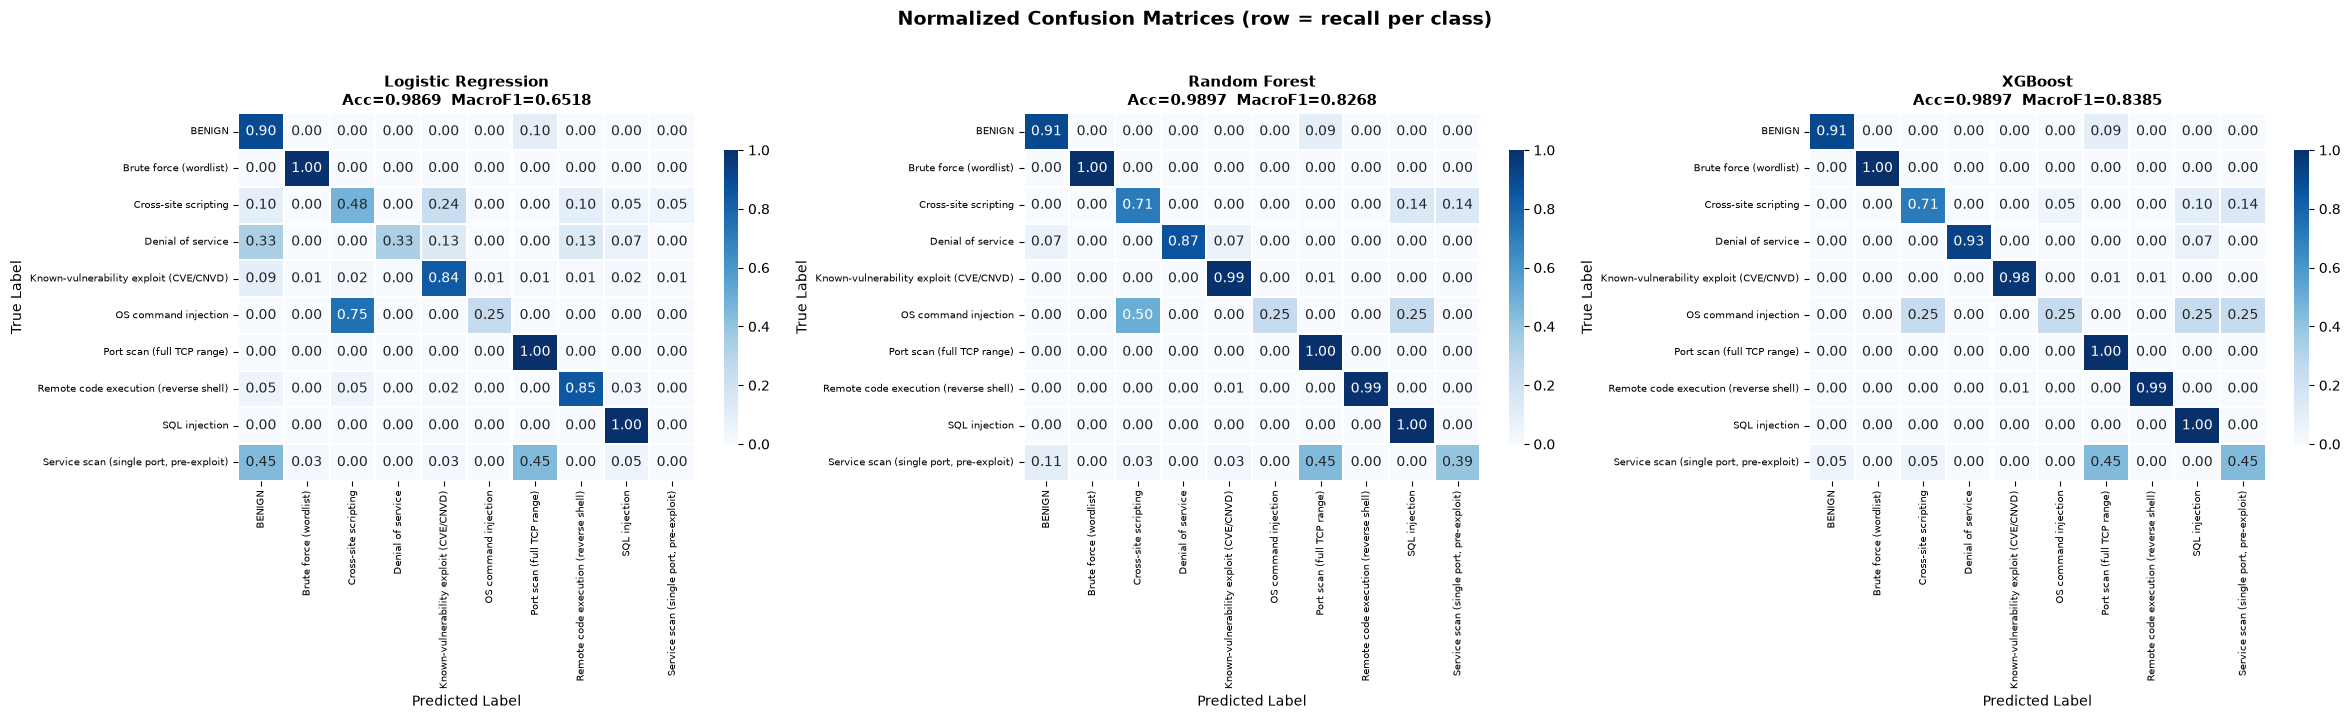

In [8]:
if sections_cfg.run_multiclass:
    show_confusion_matrices(results, y_test, mc_class_names, 'Normalized Confusion Matrices (row = recall per class)')

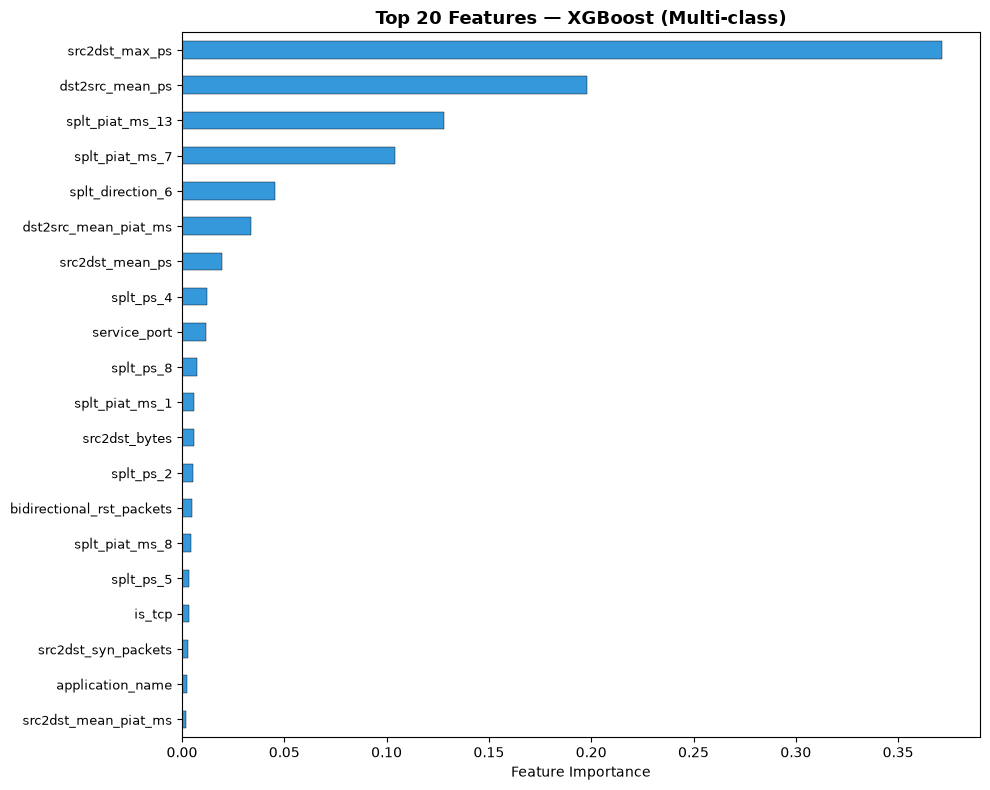

In [9]:
if sections_cfg.run_multiclass:
    show_feature_importance(trained_models, active_feature_cols, '(Multi-class)')

In [10]:
if sections_cfg.run_multiclass:
    s8_summary = show_summary(results, mc_class_names, 'Standard ML Baseline — Summary')

    # Per-class F1
    print("\n\nPer-Class F1 Score Comparison\n")
    per_class_f1 = {}
    for name, res in results.items():
        report = classification_report(y_test, res['y_pred'], labels=np.arange(len(mc_class_names)),
                                       target_names=mc_class_names, output_dict=True, zero_division=0)
        per_class_f1[name] = {cls: report[cls]['f1-score'] for cls in mc_class_names}
    f1_df = pd.DataFrame(per_class_f1).round(4)
    f1_df['Best Model'] = f1_df.apply(lambda row: f1_df.columns[row.argmax()], axis=1)
    print(f1_df.to_string())

    weak_classes = f1_df[f1_df.drop(columns='Best Model').max(axis=1) < 0.5]
    if len(weak_classes) > 0:
        print(f"\nClasses where ALL models have F1 < 0.5:")
        for cls in weak_classes.index:
            best_f1 = f1_df.drop(columns='Best Model').loc[cls].max()
            print(f"  {cls}: best F1 = {best_f1:.4f}")

Standard ML Baseline — Summary

              Model Device Accuracy Weighted F1 Macro F1 Train Time (s)
Logistic Regression    CPU   0.9869      0.9866   0.6518          238.0
      Random Forest    CPU   0.9897      0.9895   0.8268           42.1
            XGBoost    GPU   0.9897      0.9895   0.8385           39.3


Per-Class F1 Score Comparison

                                         Logistic Regression  Random Forest  XGBoost     Best Model
BENIGN                                                0.9426         0.9523   0.9523  Random Forest
Brute force (wordlist)                                0.9866         0.9999   1.0000        XGBoost
Cross-site scripting                                  0.4167         0.6977   0.6977  Random Forest
Denial of service                                     0.2857         0.8966   0.9655        XGBoost
Known-vulnerability exploit (CVE/CNVD)                0.8394         0.9805   0.9803  Random Forest
OS command injection                           

---
## Binary Classification Baseline

- **Dataset:** ML dataset
- **Split:** 70/30 stratified random (train/test)
- **Prediction:** Binary (BENIGN vs ATTACK)
- **Balanced:** No (original class distribution)

In [11]:
if sections_cfg.run_binary:
    print("=" * 70)
    print("Binary Classification Baseline")
    print("=" * 70)

    df_s9 = ml_df if data_cfg.use_ml_dataset else tl_df
    y_bin = (df_s9['Label'] != 'BENIGN').astype(int).values
    X = df_s9[active_feature_cols].to_numpy(dtype=np.float32)
    bin_class_names = np.array(['BENIGN', 'ATTACK'])

    print(f"BENIGN: {(y_bin == 0).sum():,}, ATTACK: {(y_bin == 1).sum():,}")

    X_train_bin, X_test_bin, y_train_bin, y_test_bin = train_test_split(
        X, y_bin, test_size=split_cfg.test_size, random_state=split_cfg.random_state, stratify=y_bin
    )

    scaler_bin = RobustScaler()
    X_train_bin_scaled = scaler_bin.fit_transform(X_train_bin)
    X_test_bin_scaled = scaler_bin.transform(X_test_bin)

    bin_classifiers = build_classifiers(binary=True)
    bin_results, bin_trained_models = train_and_evaluate(
        bin_classifiers, X_train_bin, y_train_bin, X_test_bin, y_test_bin,
        X_train_bin_scaled, X_test_bin_scaled, bin_class_names, "binary"
    )
    del X, X_train_bin, X_test_bin, X_train_bin_scaled, X_test_bin_scaled
    gc.collect()
else:
    print("Binary Classification Baseline DISABLED.")

Binary Classification Baseline
BENIGN: 69,362, ATTACK: 560,317


Training Logistic Regression [CPU]...


  Done in 95.6s — Accuracy: 0.9880, Weighted F1: 0.9877, Macro F1: 0.9679

Training Random Forest [CPU]...


  Done in 45.5s — Accuracy: 0.9895, Weighted F1: 0.9892, Macro F1: 0.9719

Training XGBoost [GPU]...


  Done in 5.5s — Accuracy: 0.9900, Weighted F1: 0.9897, Macro F1: 0.9733

All binary models trained.


Classification Report — Logistic Regression
              precision    recall  f1-score   support

      BENIGN     0.9959    0.8945    0.9425     20809
      ATTACK     0.9871    0.9995    0.9933    168095

    accuracy                         0.9880    188904
   macro avg     0.9915    0.9470    0.9679    188904
weighted avg     0.9881    0.9880    0.9877    188904


Classification Report — Random Forest
              precision    recall  f1-score   support

      BENIGN     0.9999    0.9044    0.9497     20809
      ATTACK     0.9883    1.0000    0.9941    168095

    accuracy                         0.9895    188904
   macro avg     0.9941    0.9522    0.9719    188904
weighted avg     0.9896    0.9895    0.9892    188904


Classification Report — XGBoost


              precision    recall  f1-score   support

      BENIGN     0.9998    0.9090    0.9522     20809
      ATTACK     0.9889    1.0000    0.9944    168095

    accuracy                         0.9900    188904
   macro avg     0.9943    0.9545    0.9733    188904
weighted avg     0.9901    0.9900    0.9897    188904




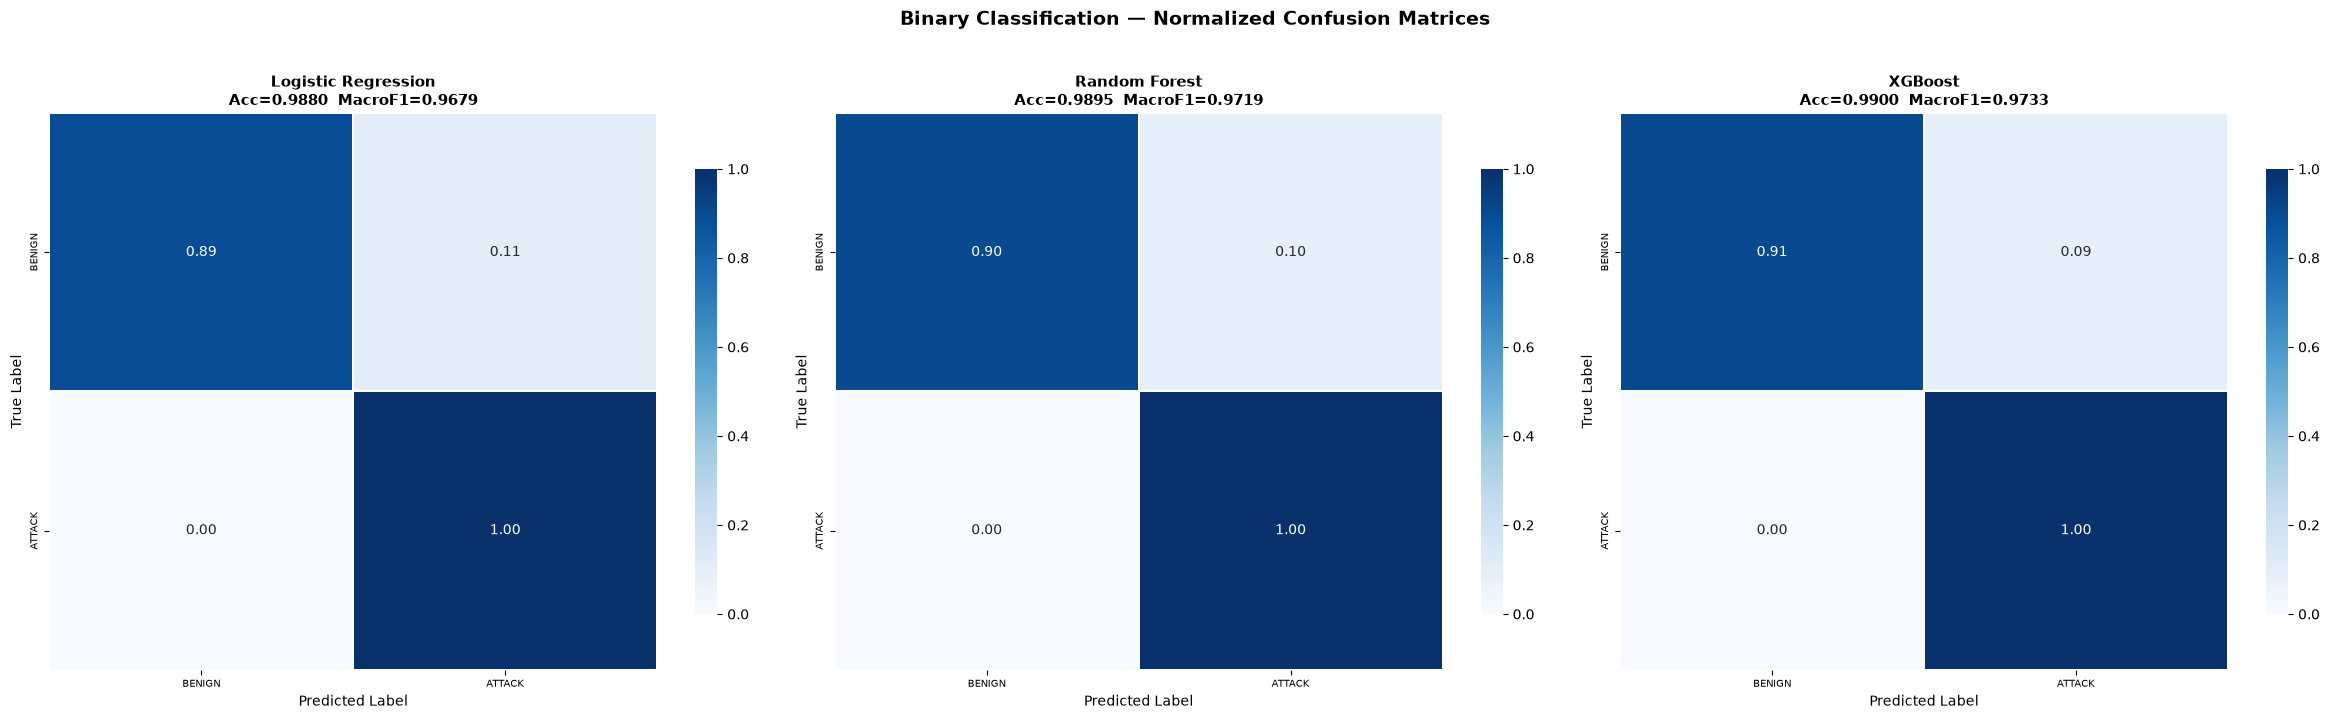

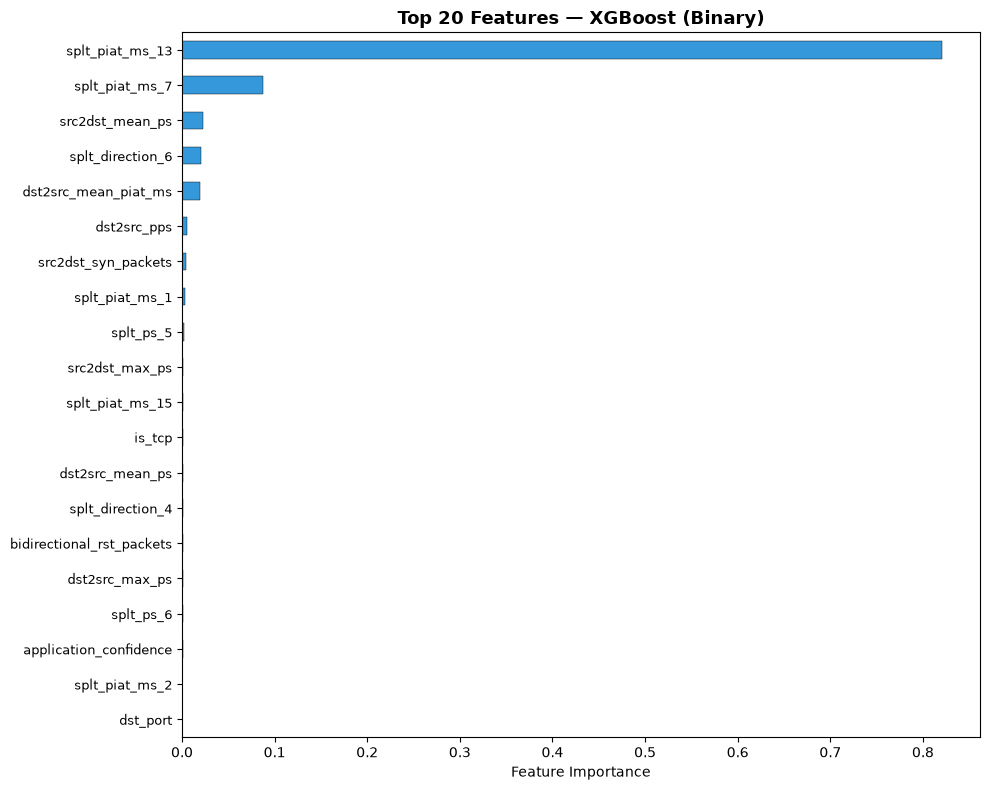

Binary Classification Baseline — Summary

              Model Device Accuracy Weighted F1 Macro F1 Train Time (s)
Logistic Regression    CPU   0.9880      0.9877   0.9679           95.6
      Random Forest    CPU   0.9895      0.9892   0.9719           45.5
            XGBoost    GPU   0.9900      0.9897   0.9733            5.5


In [12]:
if sections_cfg.run_binary:
    show_reports(bin_results, y_test_bin, bin_class_names)
    show_confusion_matrices(bin_results, y_test_bin, bin_class_names, 'Binary Classification — Normalized Confusion Matrices')
    show_feature_importance(bin_trained_models, active_feature_cols, '(Binary)')
    s9_summary = show_summary(bin_results, bin_class_names, 'Binary Classification Baseline — Summary')

---
## Balanced Binary Classification

- **Dataset:** ML dataset
- **Split:** 70/30 stratified random (train/test)
- **Prediction:** Binary (BENIGN vs ATTACK)
- **Balanced:** Yes — 50/50 BENIGN/ATTACK via undersampling the majority class (here ATTACK)

In [13]:
if sections_cfg.run_balanced:
    print("=" * 70)
    print("Balanced Binary Classification")
    print("=" * 70)

    df_s10 = ml_df if data_cfg.use_ml_dataset else tl_df
    df_s10 = df_s10.copy()
    df_s10['binary_label'] = (df_s10['Label'] != 'BENIGN').astype(int)

    attack_df = df_s10[df_s10['binary_label'] == 1]
    benign_df = df_s10[df_s10['binary_label'] == 0]

    n_attack = len(attack_df)
    n_benign = len(benign_df)
    n_min = min(n_attack, n_benign)
    if n_min == 0:
        raise ValueError("Balanced split requires both BENIGN and ATTACK samples.")

    benign_sampled = benign_df.sample(n=n_min, random_state=split_cfg.random_state)
    attack_sampled = attack_df.sample(n=n_min, random_state=split_cfg.random_state)
    balanced_df = pd.concat([benign_sampled, attack_sampled], ignore_index=True)

    print(f"Balanced: BENIGN={len(benign_sampled):,}, ATTACK={len(attack_sampled):,}, Total={len(balanced_df):,}")

    X_bal = balanced_df[active_feature_cols].to_numpy(dtype=np.float32)
    y_bal = balanced_df['binary_label'].values
    bal_class_names = np.array(['BENIGN', 'ATTACK'])

    X_train_bal, X_test_bal, y_train_bal, y_test_bal = train_test_split(
        X_bal, y_bal, test_size=split_cfg.test_size, random_state=split_cfg.random_state, stratify=y_bal
    )

    scaler_bal = RobustScaler()
    X_train_bal_scaled = scaler_bal.fit_transform(X_train_bal)
    X_test_bal_scaled = scaler_bal.transform(X_test_bal)

    bal_classifiers = build_classifiers(binary=True)
    bal_results, bal_trained_models = train_and_evaluate(
        bal_classifiers, X_train_bal, y_train_bal, X_test_bal, y_test_bal,
        X_train_bal_scaled, X_test_bal_scaled, bal_class_names, "balanced binary"
    )
    del df_s10, attack_df, benign_df, balanced_df, X_bal, X_train_bal, X_test_bal, X_train_bal_scaled, X_test_bal_scaled
    gc.collect()
else:
    print("Balanced Binary Classification DISABLED.")

Balanced Binary Classification


Balanced: BENIGN=69,362, ATTACK=69,362, Total=138,724


Training Logistic Regression [CPU]...


  Done in 35.9s — Accuracy: 0.9478, Weighted F1: 0.9477, Macro F1: 0.9477

Training Random Forest [CPU]...


  Done in 8.3s — Accuracy: 0.9525, Weighted F1: 0.9525, Macro F1: 0.9525

Training XGBoost [GPU]...


  Done in 1.9s — Accuracy: 0.9535, Weighted F1: 0.9534, Macro F1: 0.9534

All balanced binary models trained.


Classification Report — Logistic Regression
              precision    recall  f1-score   support

      BENIGN     0.9982    0.8973    0.9451     20809
      ATTACK     0.9067    0.9984    0.9503     20809

    accuracy                         0.9478     41618
   macro avg     0.9525    0.9478    0.9477     41618
weighted avg     0.9525    0.9478    0.9477     41618


Classification Report — Random Forest
              precision    recall  f1-score   support

      BENIGN     0.9955    0.9092    0.9504     20809
      ATTACK     0.9164    0.9959    0.9545     20809

    accuracy                         0.9525     41618
   macro avg     0.9560    0.9525    0.9525     41618
weighted avg     0.9560    0.9525    0.9525     41618


Classification Report — XGBoost
              precision    recall  f1-score   support

      BENIGN     0.9993    0.9077    0.9513     20809
      ATTACK     0.9155    0.9993    0.9556     20809

    accuracy                         0.9535     41618
   macro avg

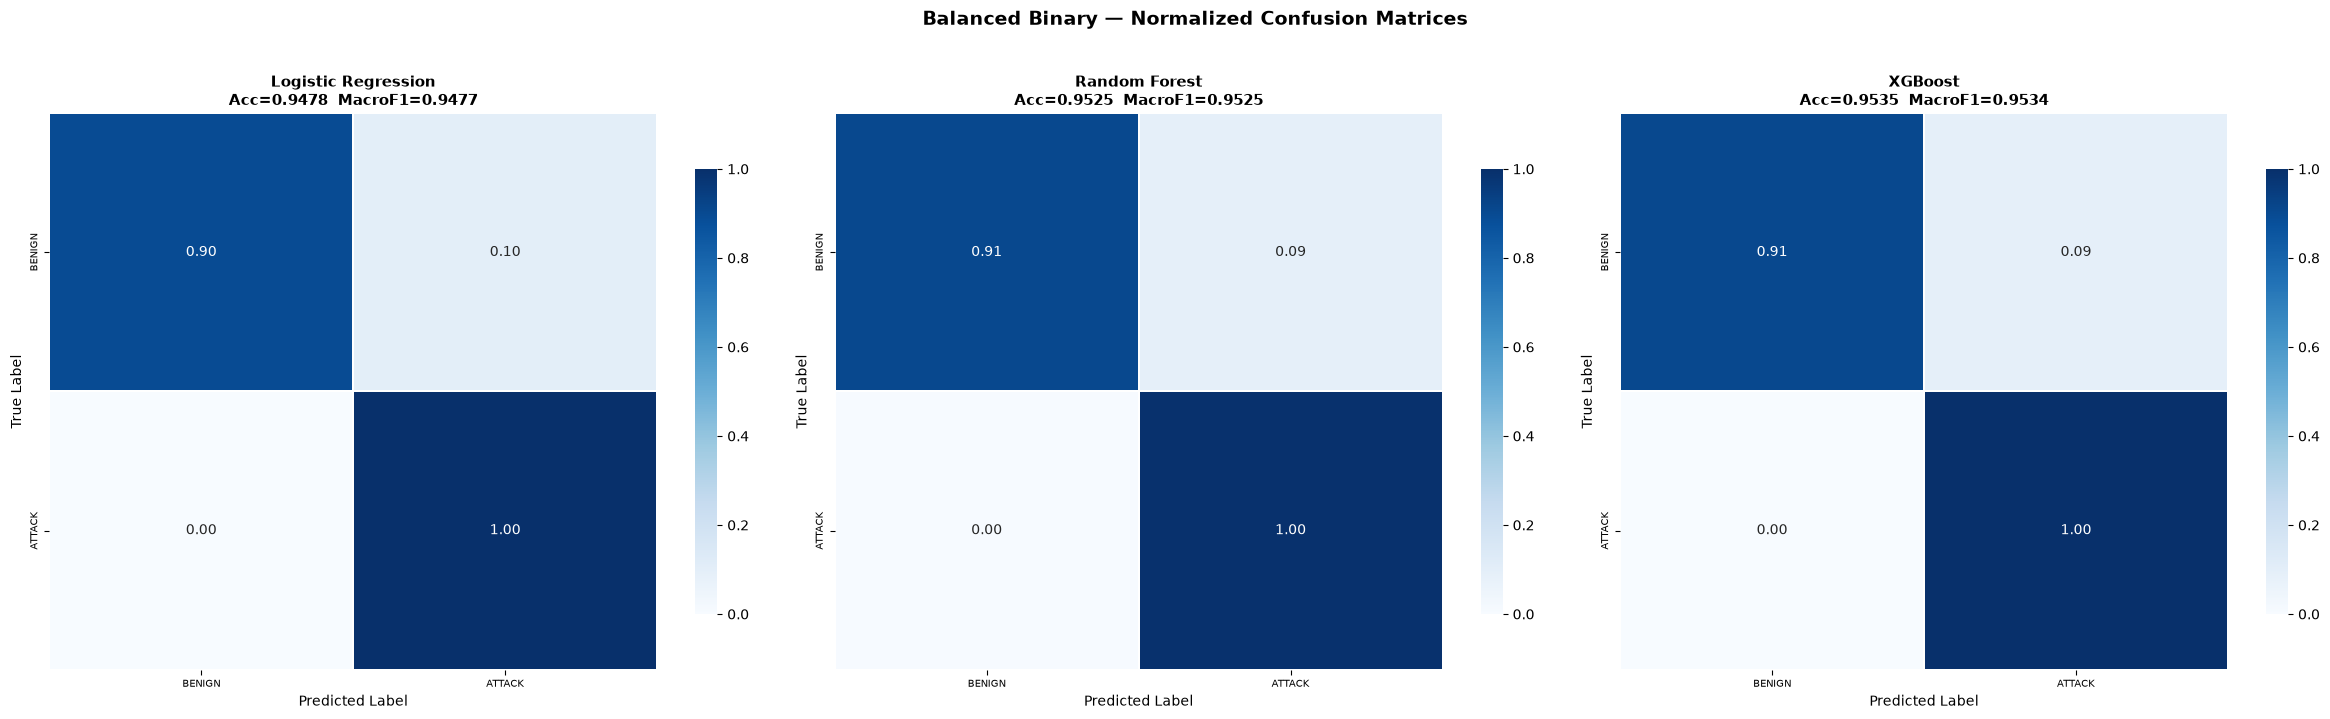

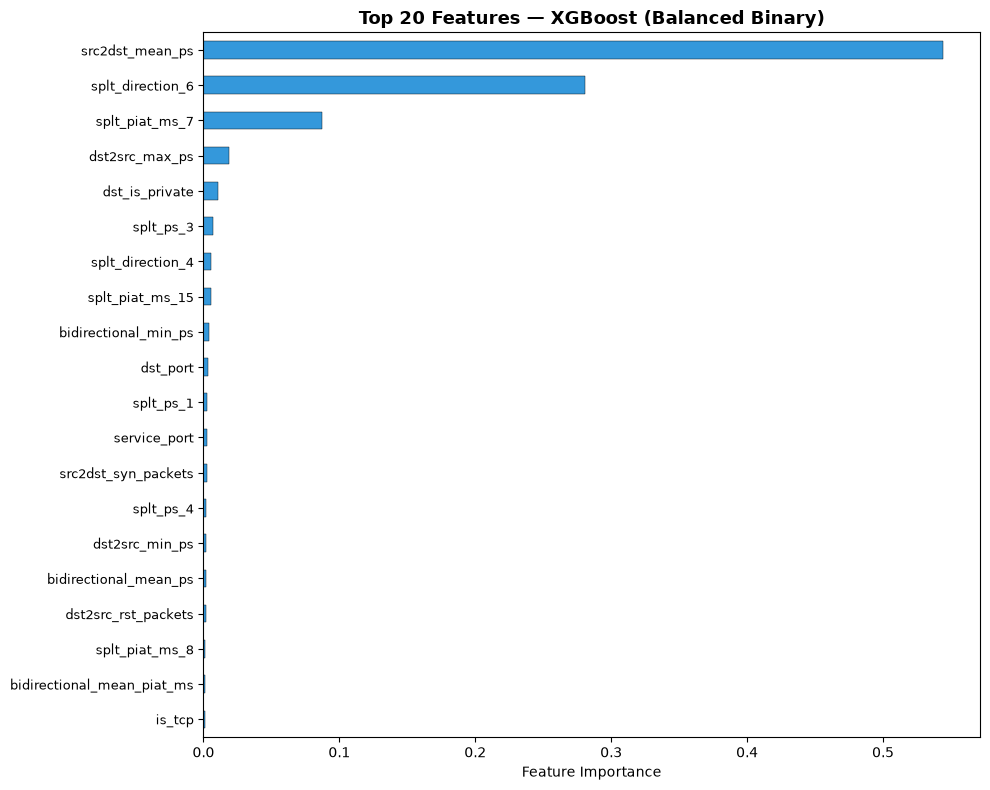

Balanced Binary Classification — Summary

              Model Device Accuracy Weighted F1 Macro F1 Train Time (s)
Logistic Regression    CPU   0.9478      0.9477   0.9477           35.9
      Random Forest    CPU   0.9525      0.9525   0.9525            8.3
            XGBoost    GPU   0.9535      0.9534   0.9534            1.9


In [14]:
if sections_cfg.run_balanced:
    show_reports(bal_results, y_test_bal, bal_class_names)
    show_confusion_matrices(bal_results, y_test_bal, bal_class_names, 'Balanced Binary — Normalized Confusion Matrices')
    show_feature_importance(bal_trained_models, active_feature_cols, '(Balanced Binary)')
    s10_summary = show_summary(bal_results, bal_class_names, 'Balanced Binary Classification — Summary')

---
## Cross-Capture Split — Train on One Capture, Test on Another

The counterpart of the CIC-IDS2017 temporal split (Mon–Thu train / Friday test): the model never sees the test capture's traffic, attackers or attack runs.

- **Dataset:** TL dataset (requires `capture_id`)
- **Split:** Captures in `train_captures` train / captures in `test_captures` test
- **Prediction:** Binary (BENIGN vs ATTACK)
- **Balanced:** Yes — training set balanced via undersampling

In [15]:
if sections_cfg.run_cross_capture:
    print("=" * 70)
    print(f"Cross-Capture Split (train {time_cfg.train_captures} / test {time_cfg.test_captures})")
    print("=" * 70)

    if tl_df_dedup is None:
        tl_df_dedup = prepare_tl_dedup(tl_df)

    print(f"Timestamp range: {tl_df_dedup['Timestamp_parsed'].min()} -> {tl_df_dedup['Timestamp_parsed'].max()}")
    print("\nRows per capture:")
    for cap, cap_df in tl_df_dedup.groupby(period_col):
        print(f"  {cap}: {len(cap_df):,} (ATTACK: {int(cap_df['binary_label'].sum()):,})  "
              f"{cap_df['Timestamp_parsed'].min():%Y-%m-%d} -> {cap_df['Timestamp_parsed'].max():%Y-%m-%d}")

    ts_train_full = tl_df_dedup[tl_df_dedup[period_col].isin(time_cfg.train_captures)]
    ts_test_full = tl_df_dedup[tl_df_dedup[period_col].isin(time_cfg.test_captures)]

    print(f"\nTrain ({', '.join(time_cfg.train_captures)}): {len(ts_train_full):,} (ATTACK: {(ts_train_full['binary_label']==1).sum():,})")
    print(f"Test ({', '.join(time_cfg.test_captures)}):  {len(ts_test_full):,} (ATTACK: {(ts_test_full['binary_label']==1).sum():,})")

    # Balance training set by undersampling the majority class
    ts_train_attack = ts_train_full[ts_train_full['binary_label'] == 1]
    ts_train_benign = ts_train_full[ts_train_full['binary_label'] == 0]
    ts_n_min = min(len(ts_train_attack), len(ts_train_benign))
    if ts_n_min == 0:
        raise ValueError("Cross-capture split requires both BENIGN and ATTACK samples in training set.")

    ts_train_benign_sampled = ts_train_benign.sample(n=ts_n_min, random_state=split_cfg.random_state)
    ts_train_attack_sampled = ts_train_attack.sample(n=ts_n_min, random_state=split_cfg.random_state)
    ts_train_balanced = pd.concat([ts_train_benign_sampled, ts_train_attack_sampled], ignore_index=True)

    print(f"Balanced train: {len(ts_train_balanced):,}")

    X_train_ts = ts_train_balanced[active_feature_cols].to_numpy(dtype=np.float32)
    y_train_ts = ts_train_balanced['binary_label'].values
    X_test_ts = ts_test_full[active_feature_cols].to_numpy(dtype=np.float32)
    y_test_ts = ts_test_full['binary_label'].values
    ts_class_names = np.array(['BENIGN', 'ATTACK'])

    scaler_ts = RobustScaler()
    X_train_ts_scaled = scaler_ts.fit_transform(X_train_ts)
    X_test_ts_scaled = scaler_ts.transform(X_test_ts)

    ts_classifiers = build_classifiers(binary=True)
    ts_results, ts_trained_models = train_and_evaluate(
        ts_classifiers, X_train_ts, y_train_ts, X_test_ts, y_test_ts,
        X_train_ts_scaled, X_test_ts_scaled, ts_class_names, "cross-capture"
    )
    del X_train_ts, X_test_ts, X_train_ts_scaled, X_test_ts_scaled
    gc.collect()
else:
    print("Cross-Capture Split DISABLED.")

Cross-Capture Split (train ['07'] / test ['10'])


Deduplication: 2,263,421 -> 629,540
Timestamp range: 2026-07-14 07:45:16.212000+00:00 -> 2026-10-13 08:40:33.588000+00:00

Rows per capture:
  07: 531,409 (ATTACK: 474,169)  2026-07-14 -> 2026-07-17
  10: 98,131 (ATTACK: 86,148)  2026-10-01 -> 2026-10-13

Train (07): 531,409 (ATTACK: 474,169)
Test (10):  98,131 (ATTACK: 86,148)


Balanced train: 114,480


Training Logistic Regression [CPU]...


  Done in 45.0s — Accuracy: 0.9962, Weighted F1: 0.9963, Macro F1: 0.9913

Training Random Forest [CPU]...


  Done in 7.3s — Accuracy: 0.9997, Weighted F1: 0.9997, Macro F1: 0.9992

Training XGBoost [GPU]...


  Done in 2.1s — Accuracy: 0.9995, Weighted F1: 0.9995, Macro F1: 0.9989

All cross-capture models trained.


Classification Report — Logistic Regression
              precision    recall  f1-score   support

      BENIGN     0.9714    0.9986    0.9848     11983
      ATTACK     0.9998    0.9959    0.9979     86148

    accuracy                         0.9962     98131
   macro avg     0.9856    0.9972    0.9913     98131
weighted avg     0.9963    0.9962    0.9963     98131


Classification Report — Random Forest
              precision    recall  f1-score   support

      BENIGN     0.9973    1.0000    0.9987     11983
      ATTACK     1.0000    0.9996    0.9998     86148

    accuracy                         0.9997     98131
   macro avg     0.9987    0.9998    0.9992     98131
weighted avg     0.9997    0.9997    0.9997     98131


Classification Report — XGBoost
              precision    recall  f1-score   support

      BENIGN     0.9963    0.9998    0.9980     11983
      ATTACK     1.0000    0.9995    0.9997     86148

    accuracy                         0.9995     98131
   macro avg

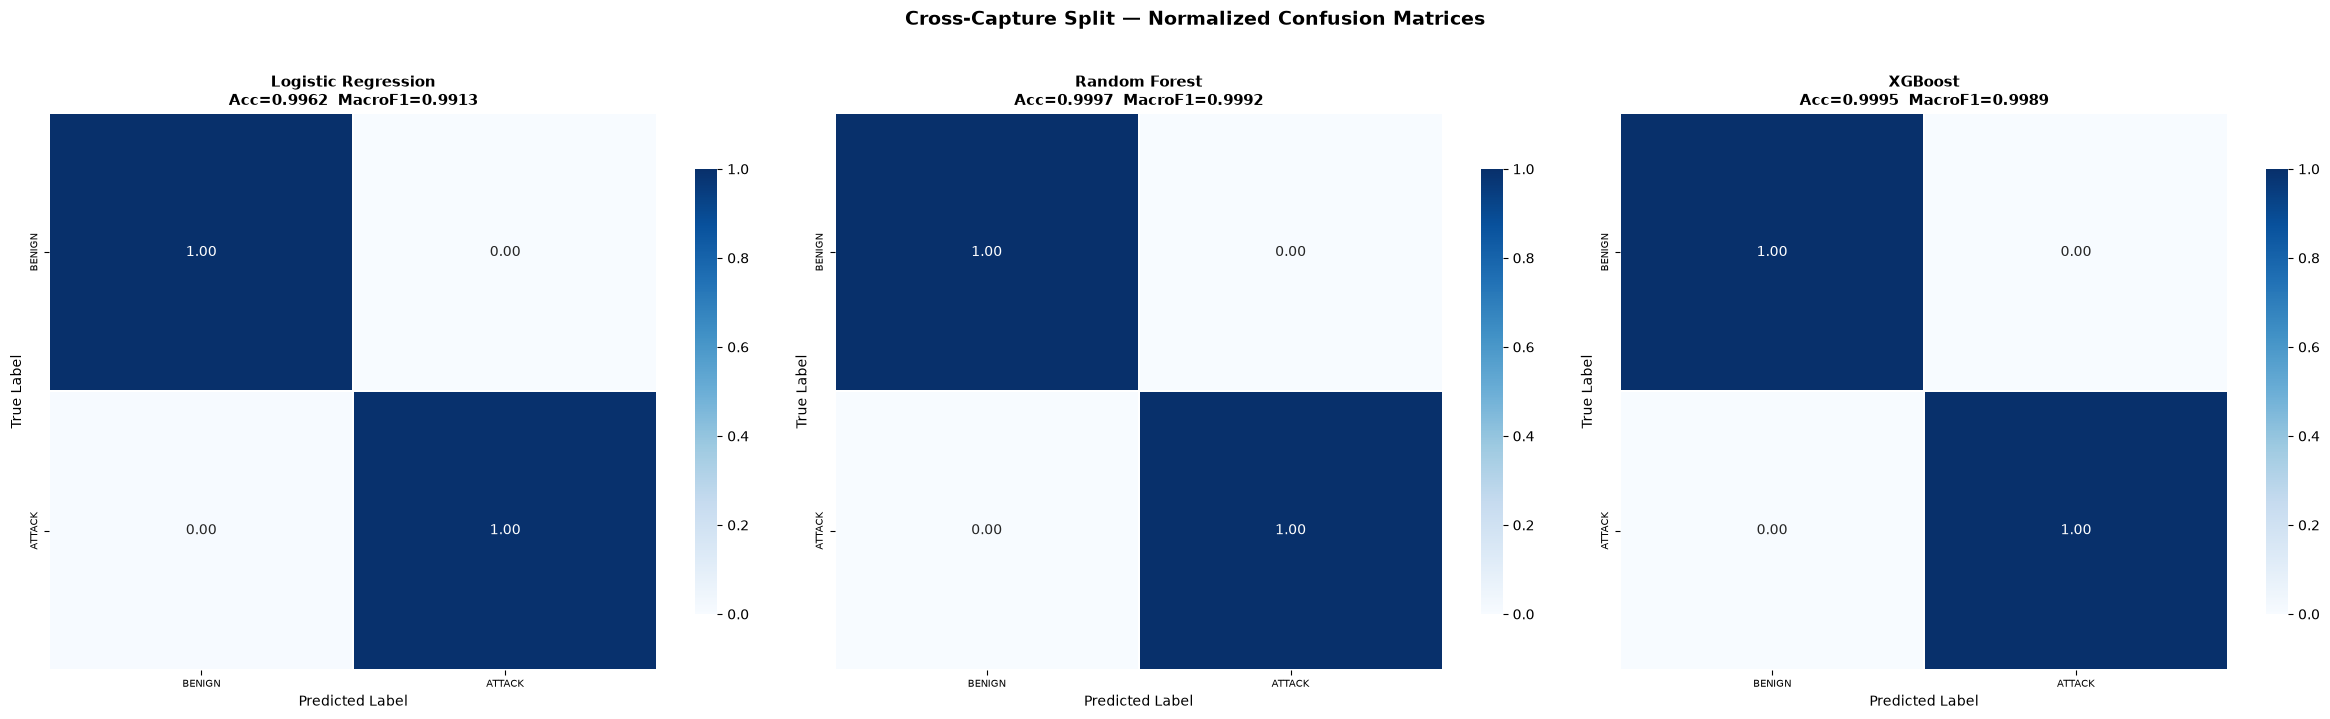

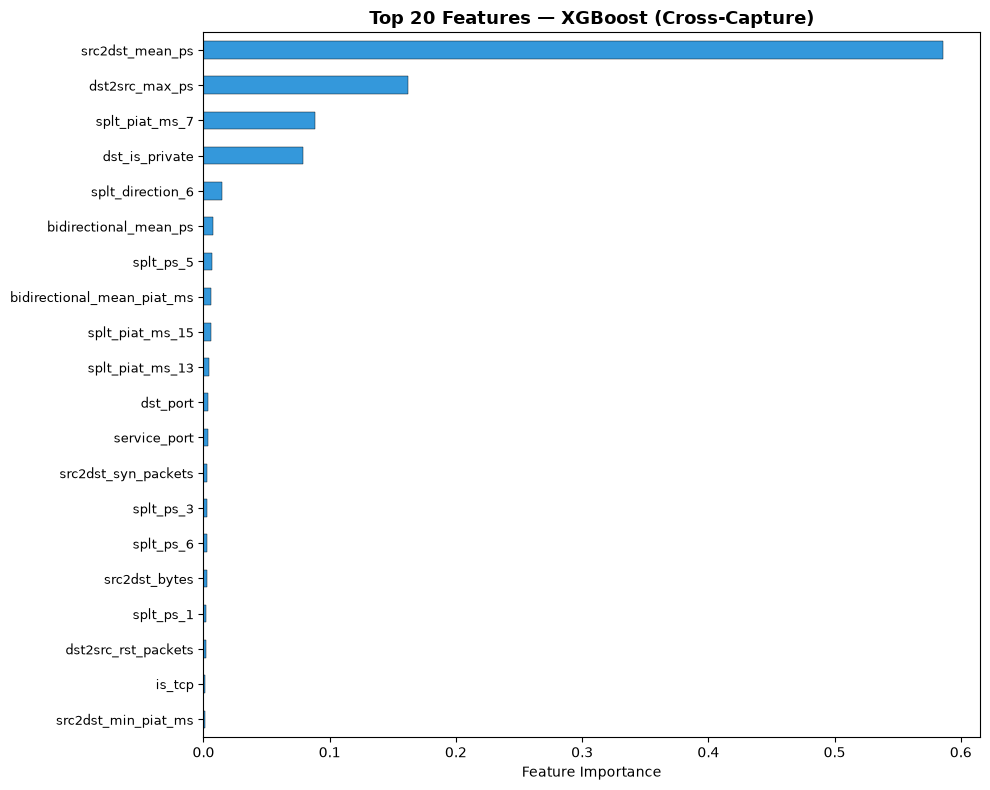

Cross-Capture Split — Summary

              Model Device Accuracy Weighted F1 Macro F1 Train Time (s)
Logistic Regression    CPU   0.9962      0.9963   0.9913           45.0
      Random Forest    CPU   0.9997      0.9997   0.9992            7.3
            XGBoost    GPU   0.9995      0.9995   0.9989            2.1


In [16]:
if isinstance(globals().get('ts_results', None), dict) and len(ts_results) > 0:
    show_reports(ts_results, y_test_ts, ts_class_names)
    show_confusion_matrices(ts_results, y_test_ts, ts_class_names, 'Cross-Capture Split — Normalized Confusion Matrices')
    show_feature_importance(ts_trained_models, active_feature_cols, '(Cross-Capture)')
    s11_summary = show_summary(ts_results, ts_class_names, 'Cross-Capture Split — Summary')

---
## Capture-Stratified Split

- **Dataset:** TL dataset (requires `capture_id`)
- **Split:** 70/30 stratified per capture (train/test)
- **Prediction:** Binary (BENIGN vs ATTACK)
- **Balanced:** Yes — training set balanced via undersampling

In [17]:
if sections_cfg.run_capture_stratified:
    print("=" * 70)
    print("Capture-Stratified Split")
    print("=" * 70)

    if tl_df_dedup is None:
        tl_df_dedup = prepare_tl_dedup(tl_df)

    ds_train_parts, ds_test_parts = [], []

    print("Per-capture stratified 70/30 split:\n")
    for cap, cap_df in tl_df_dedup.groupby(period_col):
        n_benign = (cap_df['binary_label'] == 0).sum()
        n_attack = (cap_df['binary_label'] == 1).sum()

        if n_attack < 2 or n_benign < 2:
            ds_train_parts.append(cap_df)
            print(f"  capture {cap}: {len(cap_df):>9,} rows -> all to train")
            continue

        cap_train, cap_test = train_test_split(
            cap_df, test_size=split_cfg.test_size, random_state=split_cfg.random_state, stratify=cap_df['binary_label']
        )
        ds_train_parts.append(cap_train)
        ds_test_parts.append(cap_test)
        print(f"  capture {cap}: {len(cap_df):>9,} rows -> train={len(cap_train):,}, test={len(cap_test):,}")

    ds_train_full = pd.concat(ds_train_parts, ignore_index=True)
    ds_test_full = pd.concat(ds_test_parts, ignore_index=True)

    # Balance training set by undersampling the majority class
    ds_train_attack = ds_train_full[ds_train_full['binary_label'] == 1]
    ds_train_benign = ds_train_full[ds_train_full['binary_label'] == 0]
    ds_n_min = min(len(ds_train_attack), len(ds_train_benign))
    if ds_n_min == 0:
        raise ValueError("Capture-stratified split requires both BENIGN and ATTACK samples in training set.")

    ds_train_benign_sampled = ds_train_benign.sample(n=ds_n_min, random_state=split_cfg.random_state)
    ds_train_attack_sampled = ds_train_attack.sample(n=ds_n_min, random_state=split_cfg.random_state)
    ds_train_balanced = pd.concat([ds_train_benign_sampled, ds_train_attack_sampled], ignore_index=True)

    print(f"\nBalanced train: {len(ds_train_balanced):,}, Test: {len(ds_test_full):,}")

    X_train_ds = ds_train_balanced[active_feature_cols].to_numpy(dtype=np.float32)
    y_train_ds = ds_train_balanced['binary_label'].values
    X_test_ds = ds_test_full[active_feature_cols].to_numpy(dtype=np.float32)
    y_test_ds = ds_test_full['binary_label'].values
    ds_class_names = np.array(['BENIGN', 'ATTACK'])

    scaler_ds = RobustScaler()
    X_train_ds_scaled = scaler_ds.fit_transform(X_train_ds)
    X_test_ds_scaled = scaler_ds.transform(X_test_ds)

    ds_classifiers = build_classifiers(binary=True)
    ds_results, ds_trained_models = train_and_evaluate(
        ds_classifiers, X_train_ds, y_train_ds, X_test_ds, y_test_ds,
        X_train_ds_scaled, X_test_ds_scaled, ds_class_names, "capture-stratified"
    )
    del ds_train_parts, ds_test_parts, ds_train_full, ds_test_full, X_train_ds, X_test_ds, X_train_ds_scaled, X_test_ds_scaled
    gc.collect()
else:
    print("Capture-Stratified Split DISABLED.")

Capture-Stratified Split
Per-capture stratified 70/30 split:



  capture 07:   531,409 rows -> train=371,986, test=159,423
  capture 10:    98,131 rows -> train=68,691, test=29,440



Balanced train: 96,912, Test: 188,863


Training Logistic Regression [CPU]...


  Done in 34.3s — Accuracy: 0.9875, Weighted F1: 0.9872, Macro F1: 0.9667

Training Random Forest [CPU]...


  Done in 5.3s — Accuracy: 0.9865, Weighted F1: 0.9864, Macro F1: 0.9648

Training XGBoost [GPU]...


  Done in 2.1s — Accuracy: 0.9895, Weighted F1: 0.9893, Macro F1: 0.9721

All capture-stratified models trained.


Classification Report — Logistic Regression
              precision    recall  f1-score   support

      BENIGN     0.9845    0.9001    0.9404     20767
      ATTACK     0.9878    0.9982    0.9930    168096

    accuracy                         0.9875    188863
   macro avg     0.9861    0.9492    0.9667    188863
weighted avg     0.9874    0.9875    0.9872    188863


Classification Report — Random Forest
              precision    recall  f1-score   support

      BENIGN     0.9639    0.9117    0.9371     20767
      ATTACK     0.9892    0.9958    0.9925    168096

    accuracy                         0.9865    188863
   macro avg     0.9765    0.9538    0.9648    188863
weighted avg     0.9864    0.9865    0.9864    188863


Classification Report — XGBoost


              precision    recall  f1-score   support

      BENIGN     0.9932    0.9106    0.9501     20767
      ATTACK     0.9891    0.9992    0.9941    168096

    accuracy                         0.9895    188863
   macro avg     0.9911    0.9549    0.9721    188863
weighted avg     0.9895    0.9895    0.9893    188863




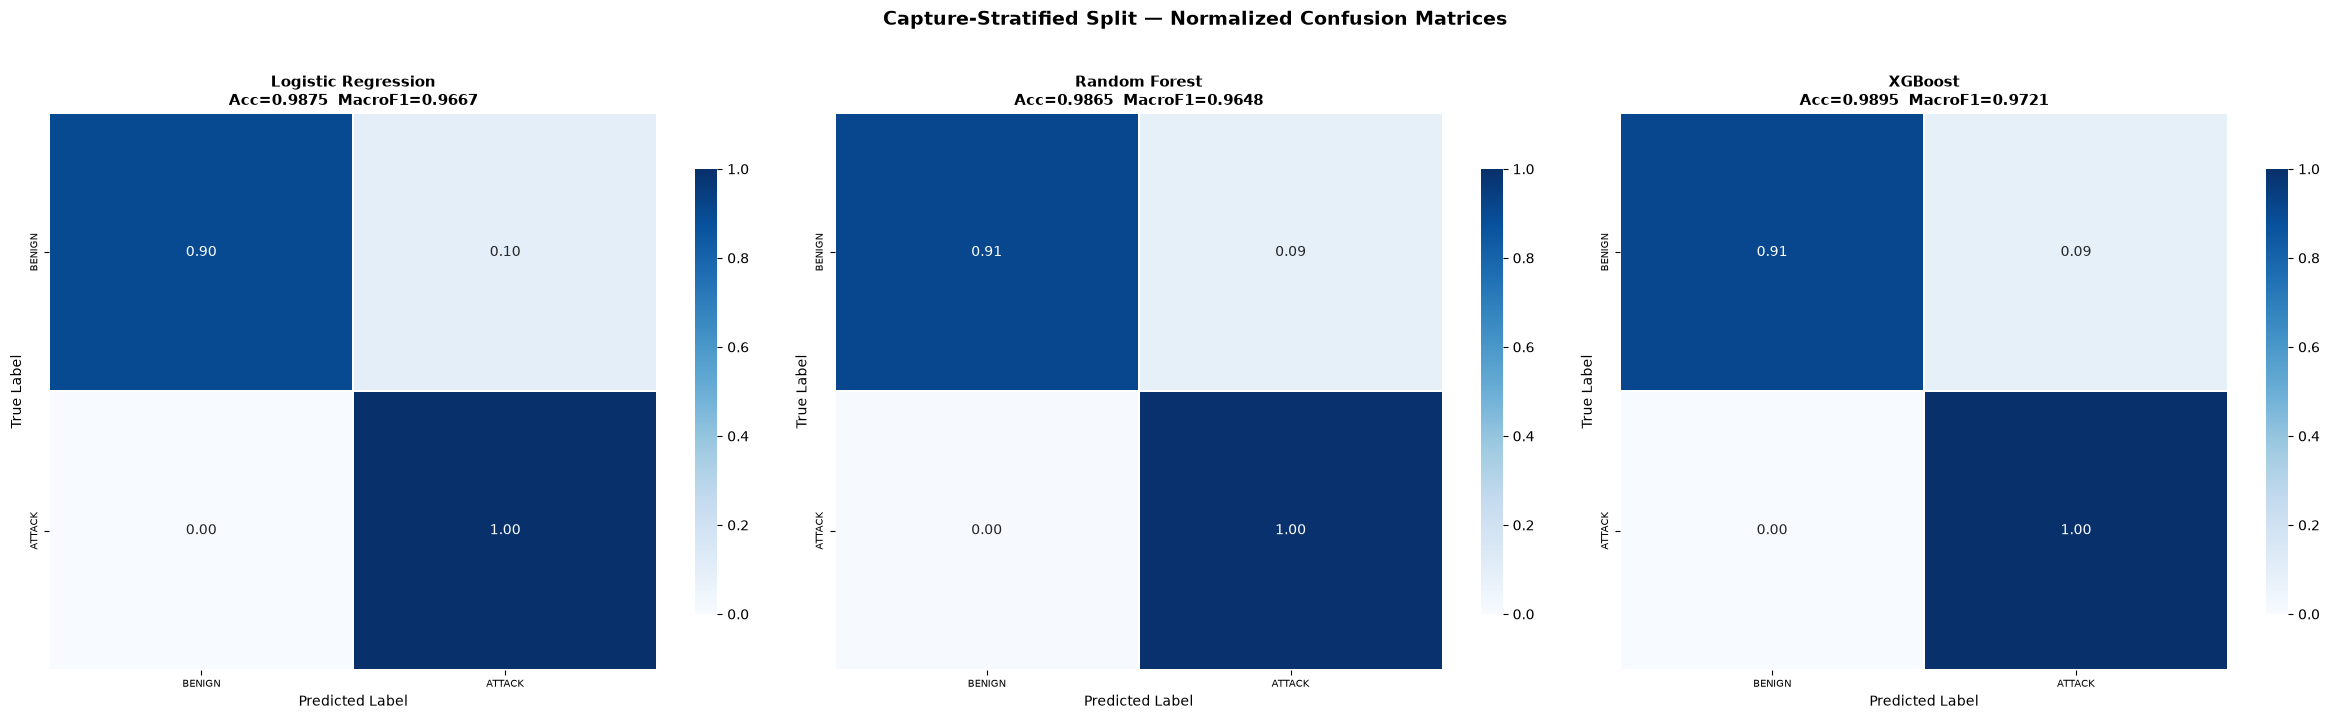

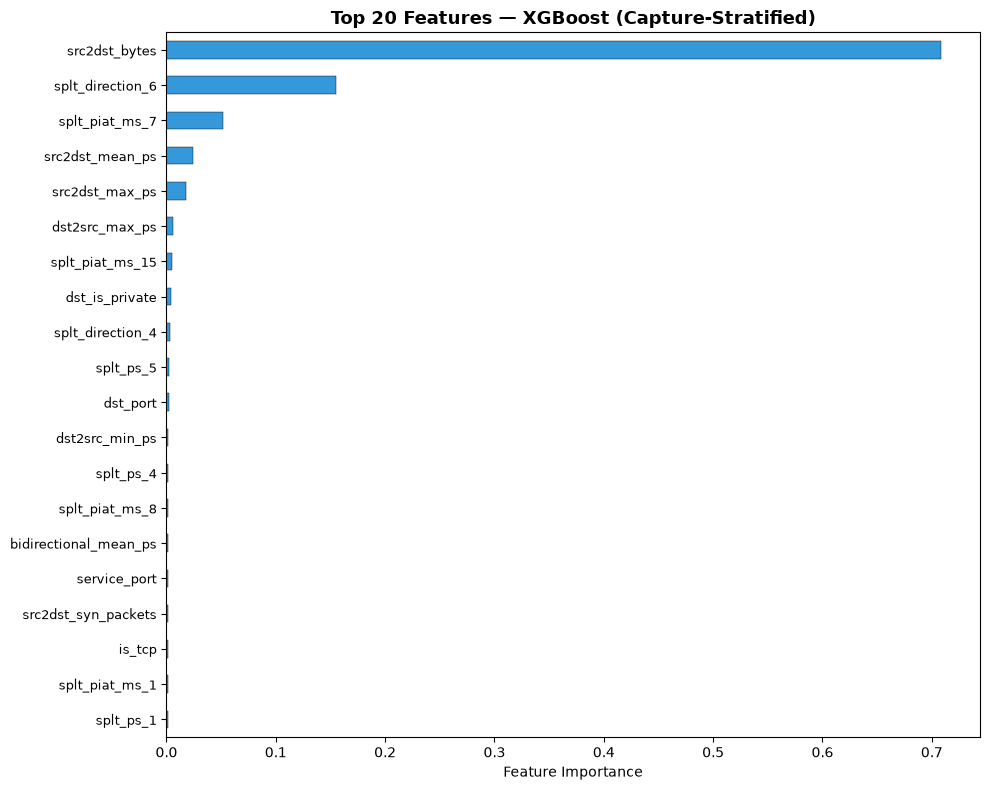

Capture-Stratified Split — Summary

              Model Device Accuracy Weighted F1 Macro F1 Train Time (s)
Logistic Regression    CPU   0.9875      0.9872   0.9667           34.3
      Random Forest    CPU   0.9865      0.9864   0.9648            5.3
            XGBoost    GPU   0.9895      0.9893   0.9721            2.1


In [18]:
if isinstance(globals().get('ds_results', None), dict) and len(ds_results) > 0:
    show_reports(ds_results, y_test_ds, ds_class_names)
    show_confusion_matrices(ds_results, y_test_ds, ds_class_names, 'Capture-Stratified Split — Normalized Confusion Matrices')
    show_feature_importance(ds_trained_models, active_feature_cols, '(Capture-Stratified)')
    s12_summary = show_summary(ds_results, ds_class_names, 'Capture-Stratified Split — Summary')

---
## Chronological Split

- **Dataset:** TL dataset (requires timestamps)
- **Split:** 70/15/15 chronological per capture (train/val/test)
- **Prediction:** Binary (BENIGN vs ATTACK)
- **Balanced:** Yes — training set balanced via undersampling
- **Early stopping:** XGBoost uses validation set for early stopping

In [19]:
if sections_cfg.run_chronological:
    print("=" * 70)
    print("Chronological Split (70/15/15 per capture)")
    print("=" * 70)

    if tl_df_dedup is None:
        tl_df_dedup = prepare_tl_dedup(tl_df)

    cs_train_parts, cs_val_parts, cs_test_parts = [], [], []

    print("Per-capture chronological 70/15/15 split:\n")
    for cap, cap_df in tl_df_dedup.groupby(period_col):
        cap_sorted = cap_df.sort_values('Timestamp_parsed', kind='stable').reset_index(drop=True)
        n = len(cap_sorted)

        train_end = int(n * 0.70)
        val_end = int(n * 0.85)

        cs_cap_train = cap_sorted.iloc[:train_end]
        cs_cap_val = cap_sorted.iloc[train_end:val_end]
        cs_cap_test = cap_sorted.iloc[val_end:]

        cs_train_parts.append(cs_cap_train)
        cs_val_parts.append(cs_cap_val)
        cs_test_parts.append(cs_cap_test)

        print(f"  capture {cap}: {n:>9,} -> train={len(cs_cap_train):,} (ATTACK {int(cs_cap_train['binary_label'].sum()):,}), "
              f"val={len(cs_cap_val):,} (ATTACK {int(cs_cap_val['binary_label'].sum()):,}), "
              f"test={len(cs_cap_test):,} (ATTACK {int(cs_cap_test['binary_label'].sum()):,})")

    cs_train_full = pd.concat(cs_train_parts, ignore_index=True)
    cs_val_full = pd.concat(cs_val_parts, ignore_index=True)
    cs_test_full = pd.concat(cs_test_parts, ignore_index=True)

    # Balance training set by undersampling the majority class
    cs_train_attack = cs_train_full[cs_train_full['binary_label'] == 1]
    cs_train_benign = cs_train_full[cs_train_full['binary_label'] == 0]
    cs_n_min = min(len(cs_train_attack), len(cs_train_benign))
    if cs_n_min == 0:
        raise ValueError("Chronological split requires both BENIGN and ATTACK samples in training set.")

    cs_train_benign_sampled = cs_train_benign.sample(n=cs_n_min, random_state=split_cfg.random_state)
    cs_train_attack_sampled = cs_train_attack.sample(n=cs_n_min, random_state=split_cfg.random_state)
    cs_train_balanced = pd.concat([cs_train_benign_sampled, cs_train_attack_sampled], ignore_index=True)

    print(f"\nBalanced train: {len(cs_train_balanced):,}, Val: {len(cs_val_full):,}, Test: {len(cs_test_full):,}")

    X_train_cs = cs_train_balanced[active_feature_cols].to_numpy(dtype=np.float32)
    y_train_cs = cs_train_balanced['binary_label'].values
    X_val_cs = cs_val_full[active_feature_cols].to_numpy(dtype=np.float32)
    y_val_cs = cs_val_full['binary_label'].values
    X_test_cs = cs_test_full[active_feature_cols].to_numpy(dtype=np.float32)
    y_test_cs = cs_test_full['binary_label'].values
    cs_class_names = np.array(['BENIGN', 'ATTACK'])

    scaler_cs = RobustScaler()
    X_train_cs_scaled = scaler_cs.fit_transform(X_train_cs)
    X_val_cs_scaled = scaler_cs.transform(X_val_cs)
    X_test_cs_scaled = scaler_cs.transform(X_test_cs)

    cs_classifiers = build_classifiers(binary=True, use_early_stopping=True)
    cs_results, cs_trained_models = train_and_evaluate(
        cs_classifiers, X_train_cs, y_train_cs, X_test_cs, y_test_cs,
        X_train_cs_scaled, X_test_cs_scaled, cs_class_names, "chronological",
        X_val=X_val_cs, y_val=y_val_cs, X_val_scaled=X_val_cs_scaled
    )
    del cs_train_parts, cs_val_parts, cs_test_parts, cs_train_full, cs_val_full, cs_test_full
    del X_train_cs, X_val_cs, X_test_cs, X_train_cs_scaled, X_val_cs_scaled, X_test_cs_scaled
    gc.collect()
else:
    print("Chronological Split DISABLED.")

Chronological Split (70/15/15 per capture)
Per-capture chronological 70/15/15 split:

  capture 07:   531,409 -> train=371,986 (ATTACK 332,084), val=79,711 (ATTACK 75,248), test=79,712 (ATTACK 66,837)
  capture 10:    98,131 -> train=68,691 (ATTACK 64,543), val=14,720 (ATTACK 14,206), test=14,720 (ATTACK 7,399)



Balanced train: 88,100, Val: 94,431, Test: 94,432


Training Logistic Regression [CPU]...


  Done in 33.2s — Accuracy: 0.9948, Weighted F1: 0.9948, Macro F1: 0.9923

Training Random Forest [CPU]...


  Done in 4.8s — Accuracy: 0.9993, Weighted F1: 0.9993, Macro F1: 0.9989

Training XGBoost [GPU]...


  XGBoost stopped at 312 trees


  Done in 3.1s — Accuracy: 0.9995, Weighted F1: 0.9995, Macro F1: 0.9992

All chronological models trained.


Classification Report — Logistic Regression
              precision    recall  f1-score   support

      BENIGN     0.9802    0.9958    0.9879     20196
      ATTACK     0.9989    0.9945    0.9967     74236

    accuracy                         0.9948     94432
   macro avg     0.9895    0.9952    0.9923     94432
weighted avg     0.9949    0.9948    0.9948     94432


Classification Report — Random Forest
              precision    recall  f1-score   support

      BENIGN     0.9966    1.0000    0.9983     20196
      ATTACK     1.0000    0.9991    0.9995     74236

    accuracy                         0.9993     94432
   macro avg     0.9983    0.9995    0.9989     94432
weighted avg     0.9993    0.9993    0.9993     94432


Classification Report — XGBoost
              precision    recall  f1-score   support

      BENIGN     0.9979    0.9996    0.9988     20196
      ATTACK     0.9999    0.9994    0.9997     74236

    accuracy                         0.9995     94432
   macro avg

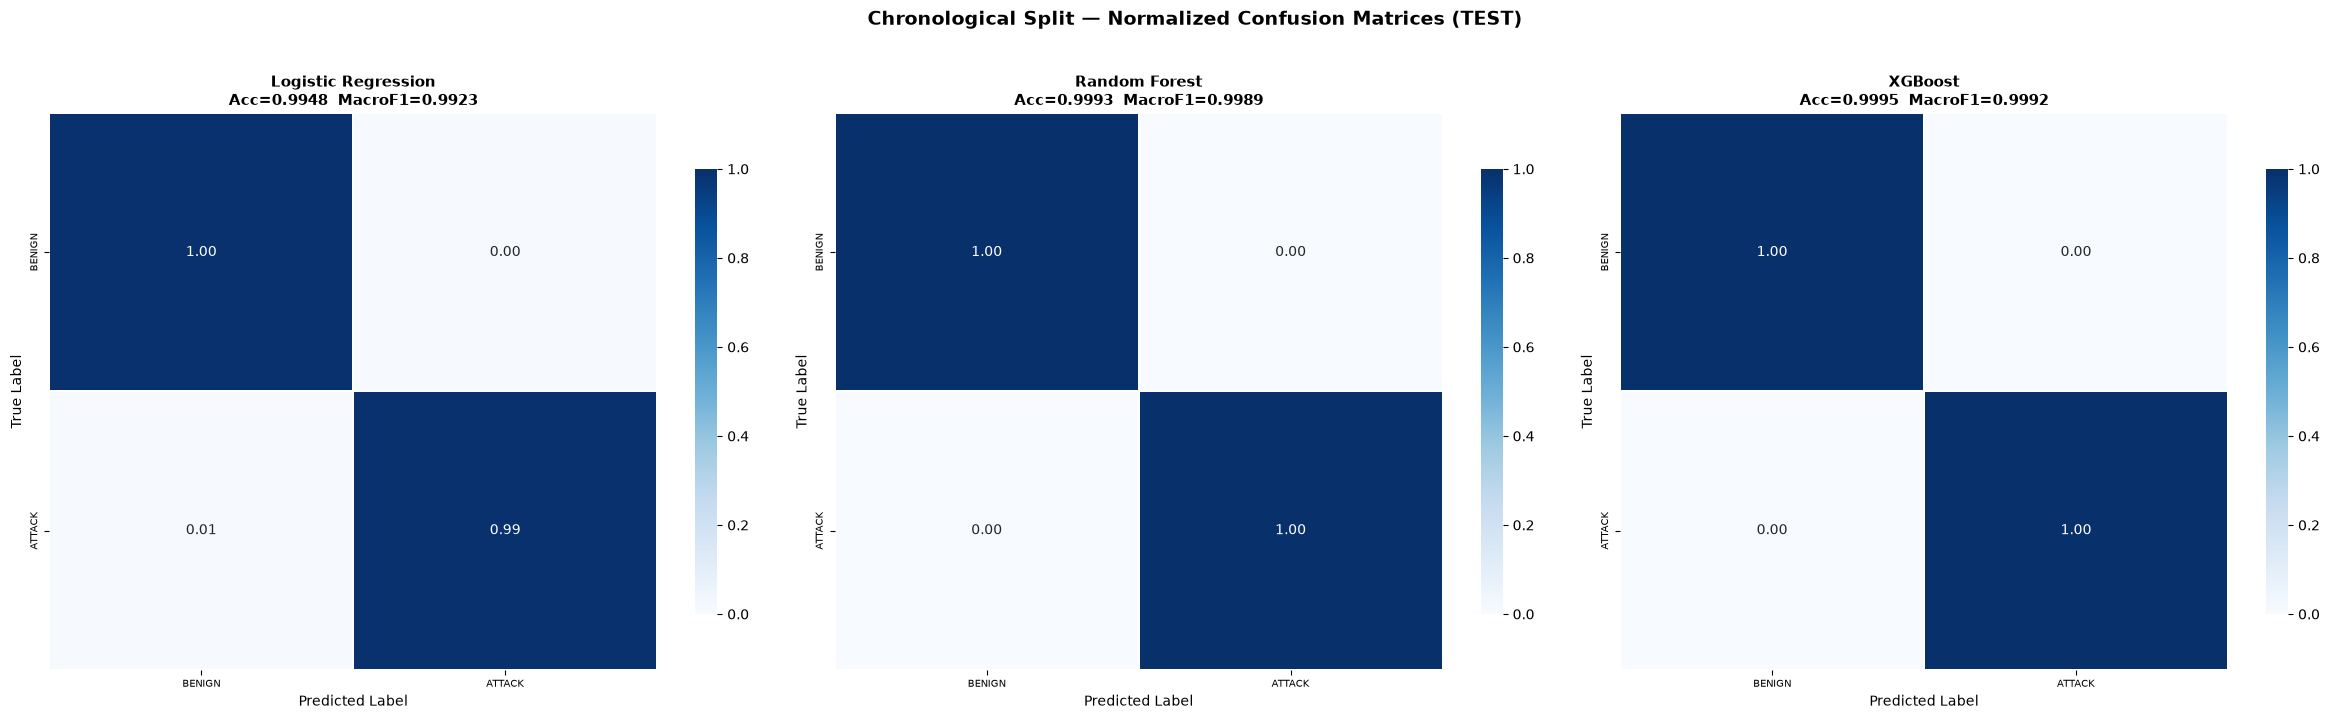

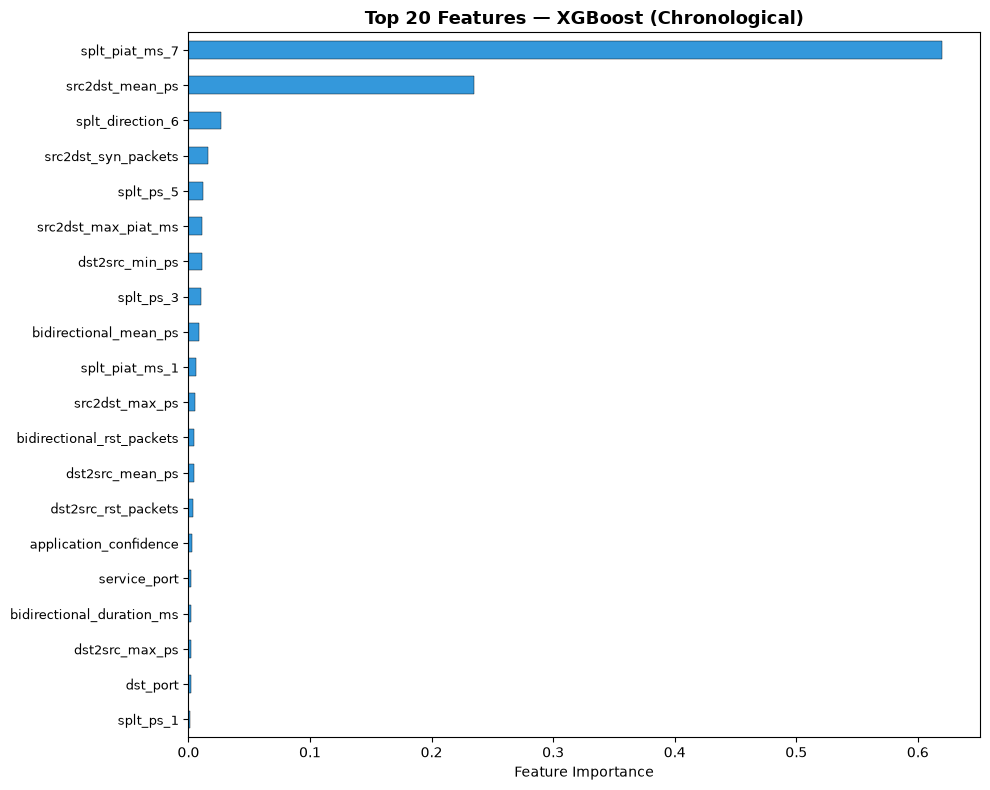

Chronological Split — Summary

              Model Device Accuracy Weighted F1 Macro F1 Train Time (s) Val Accuracy Val Macro F1
Logistic Regression    CPU   0.9948      0.9948   0.9923           33.2       0.9745       0.8511
      Random Forest    CPU   0.9993      0.9993   0.9989            4.8       0.9805       0.8835
            XGBoost    GPU   0.9995      0.9995   0.9992            3.1       0.9806       0.8842


In [20]:
if isinstance(globals().get('cs_results', None), dict) and len(cs_results) > 0:
    show_reports(cs_results, y_test_cs, cs_class_names)
    show_confusion_matrices(cs_results, y_test_cs, cs_class_names, 'Chronological Split — Normalized Confusion Matrices (TEST)')
    show_feature_importance(cs_trained_models, active_feature_cols, '(Chronological)')
    s13_summary = show_summary(cs_results, cs_class_names, 'Chronological Split — Summary')

---
## Per-Label Stratified Chronological Split

- **Dataset:** TL dataset (requires timestamps)
- **Split:** 70/15/15 chronological per label (train/val/test)
- **Prediction:** Binary (BENIGN vs ATTACK)
- **Balanced:** Yes — training set balanced via undersampling
- **Early stopping:** XGBoost uses validation set for early stopping
- **Note:** Every label with at least 3 flows appears in train, val, and test. The XGBoost test predictions are saved for `03_graph_ml.ipynb`, which rebuilds the same split.

In [21]:
if sections_cfg.run_label_stratified:
    print("=" * 70)
    print("Per-Label Stratified Chronological Split")
    print("=" * 70)

    if tl_df_dedup is None:
        tl_df_dedup = prepare_tl_dedup(tl_df)

    ls_train_parts, ls_val_parts, ls_test_parts = [], [], []

    print("Per-label chronological 70/15/15 split:\n")
    print(f"{'Label':<44} {'Total':>9} {'Train':>9} {'Val':>8} {'Test':>8}")
    print("-" * 82)

    for label in sorted(tl_df_dedup['Label'].unique()):
        label_df = tl_df_dedup[tl_df_dedup['Label'] == label]
        label_sorted = label_df.sort_values('Timestamp_parsed', kind='stable').reset_index(drop=True)
        n = len(label_sorted)

        train_end = int(n * 0.70)
        val_end = int(n * 0.85)

        ls_label_train = label_sorted.iloc[:train_end]
        ls_label_val = label_sorted.iloc[train_end:val_end]
        ls_label_test = label_sorted.iloc[val_end:]

        ls_train_parts.append(ls_label_train)
        ls_val_parts.append(ls_label_val)
        ls_test_parts.append(ls_label_test)

        print(f"  {label:<42} {n:>9,} {len(ls_label_train):>9,} {len(ls_label_val):>8,} {len(ls_label_test):>8,}")

    ls_train_full = pd.concat(ls_train_parts, ignore_index=True)
    ls_val_full = pd.concat(ls_val_parts, ignore_index=True)
    ls_test_full = pd.concat(ls_test_parts, ignore_index=True)

    print(f"\nTrain: {len(ls_train_full):,}, Val: {len(ls_val_full):,}, Test: {len(ls_test_full):,}")

    # Verify all attack types present
    ls_train_atypes = set(ls_train_full[ls_train_full['binary_label'] == 1]['Label'].unique())
    ls_val_atypes = set(ls_val_full[ls_val_full['binary_label'] == 1]['Label'].unique())
    ls_test_atypes = set(ls_test_full[ls_test_full['binary_label'] == 1]['Label'].unique())
    print(f"Attack types — train: {len(ls_train_atypes)}, val: {len(ls_val_atypes)}, test: {len(ls_test_atypes)}")

    # Balance training set by undersampling the majority class
    ls_train_attack = ls_train_full[ls_train_full['binary_label'] == 1]
    ls_train_benign = ls_train_full[ls_train_full['binary_label'] == 0]
    ls_n_min = min(len(ls_train_attack), len(ls_train_benign))
    if ls_n_min == 0:
        raise ValueError("Per-label chronological split requires both BENIGN and ATTACK samples in training set.")

    ls_train_benign_sampled = ls_train_benign.sample(n=ls_n_min, random_state=split_cfg.random_state)
    ls_train_attack_sampled = ls_train_attack.sample(n=ls_n_min, random_state=split_cfg.random_state)
    ls_train_balanced = pd.concat([ls_train_benign_sampled, ls_train_attack_sampled], ignore_index=True)

    print(f"Balanced train: {len(ls_train_balanced):,}")

    X_train_ls = ls_train_balanced[active_feature_cols].to_numpy(dtype=np.float32)
    y_train_ls = ls_train_balanced['binary_label'].values
    X_val_ls = ls_val_full[active_feature_cols].to_numpy(dtype=np.float32)
    y_val_ls = ls_val_full['binary_label'].values
    X_test_ls = ls_test_full[active_feature_cols].to_numpy(dtype=np.float32)
    y_test_ls = ls_test_full['binary_label'].values
    ls_class_names = np.array(['BENIGN', 'ATTACK'])

    scaler_ls = RobustScaler()
    X_train_ls_scaled = scaler_ls.fit_transform(X_train_ls)
    X_val_ls_scaled = scaler_ls.transform(X_val_ls)
    X_test_ls_scaled = scaler_ls.transform(X_test_ls)

    ls_classifiers = build_classifiers(binary=True, use_early_stopping=True)
    ls_results, ls_trained_models = train_and_evaluate(
        ls_classifiers, X_train_ls, y_train_ls, X_test_ls, y_test_ls,
        X_train_ls_scaled, X_test_ls_scaled, ls_class_names, "per-label chrono",
        X_val=X_val_ls, y_val=y_val_ls, X_val_scaled=X_val_ls_scaled
    )
    del X_train_ls, X_val_ls, X_test_ls, X_train_ls_scaled, X_val_ls_scaled, X_test_ls_scaled
    gc.collect()
else:
    print("Per-Label Stratified Chronological Split DISABLED.")

Per-Label Stratified Chronological Split
Per-label chronological 70/15/15 split:

Label                                            Total     Train      Val     Test
----------------------------------------------------------------------------------
  BENIGN                                        69,223    48,456   10,383   10,384
  ms2-dvwa-cmdinject                                13         9        2        2
  ms2-dvwa-cmdinject-portscan                        9         6        1        2
  ms2-dvwa-lfi                                       4         2        1        1
  ms2-dvwa-lfi-portscan                              7         4        1        2
  ms2-dvwa-sqli-manual                              20        14        3        3
  ms2-dvwa-sqli-manual-portscan                      7         4        1        2
  ms2-dvwa-xss-reflected                            51        35        8        8
  ms2-dvwa-xss-reflected-portscan                    9         6        1        2
  ms2

  nmap-full-portscan                           489,830   342,881   73,474   73,475
  vulnhub-1panel-cve-2024-39907                    218       152       33       33
  vulnhub-1panel-cve-2024-39907-portscan             2         1        0        1
  vulnhub-activemq-cve-2022-41678                   85        59       13       13
  vulnhub-activemq-cve-2022-41678-portscan           8         5        1        2
  vulnhub-activemq-cve-2026-34197                   21        14        3        4
  vulnhub-activemq-cve-2026-34197-portscan           1         0        0        1
  vulnhub-airflow-cve-2020-11978                    39        27        6        6
  vulnhub-airflow-cve-2020-11978-portscan            1         0        0        1
  vulnhub-airflow-cve-2020-11981                     9         6        1        2
  vulnhub-airflow-cve-2020-11981-portscan            1         0        0        1
  vulnhub-airflow-cve-2020-17526                    36        25        5        6
  vu

Attack types — train: 49, val: 43, test: 53
Balanced train: 96,912


Training Logistic Regression [CPU]...


  Done in 36.4s — Accuracy: 0.9984, Weighted F1: 0.9984, Macro F1: 0.9960

Training Random Forest [CPU]...


  Done in 5.6s — Accuracy: 0.9997, Weighted F1: 0.9997, Macro F1: 0.9992

Training XGBoost [GPU]...


  XGBoost stopped at 41 trees


  Done in 1.3s — Accuracy: 0.9997, Weighted F1: 0.9997, Macro F1: 0.9993

All per-label chrono models trained.


Classification Report — Logistic Regression
              precision    recall  f1-score   support

      BENIGN     0.9863    0.9995    0.9929     10384
      ATTACK     0.9999    0.9983    0.9991     84076

    accuracy                         0.9984     94460
   macro avg     0.9931    0.9989    0.9960     94460
weighted avg     0.9984    0.9984    0.9984     94460


Classification Report — Random Forest
              precision    recall  f1-score   support

      BENIGN     0.9973    1.0000    0.9987     10384
      ATTACK     1.0000    0.9997    0.9998     84076

    accuracy                         0.9997     94460
   macro avg     0.9987    0.9998    0.9992     94460
weighted avg     0.9997    0.9997    0.9997     94460


Classification Report — XGBoost
              precision    recall  f1-score   support

      BENIGN     0.9975    1.0000    0.9987     10384
      ATTACK     1.0000    0.9997    0.9998     84076

    accuracy                         0.9997     94460
   macro avg

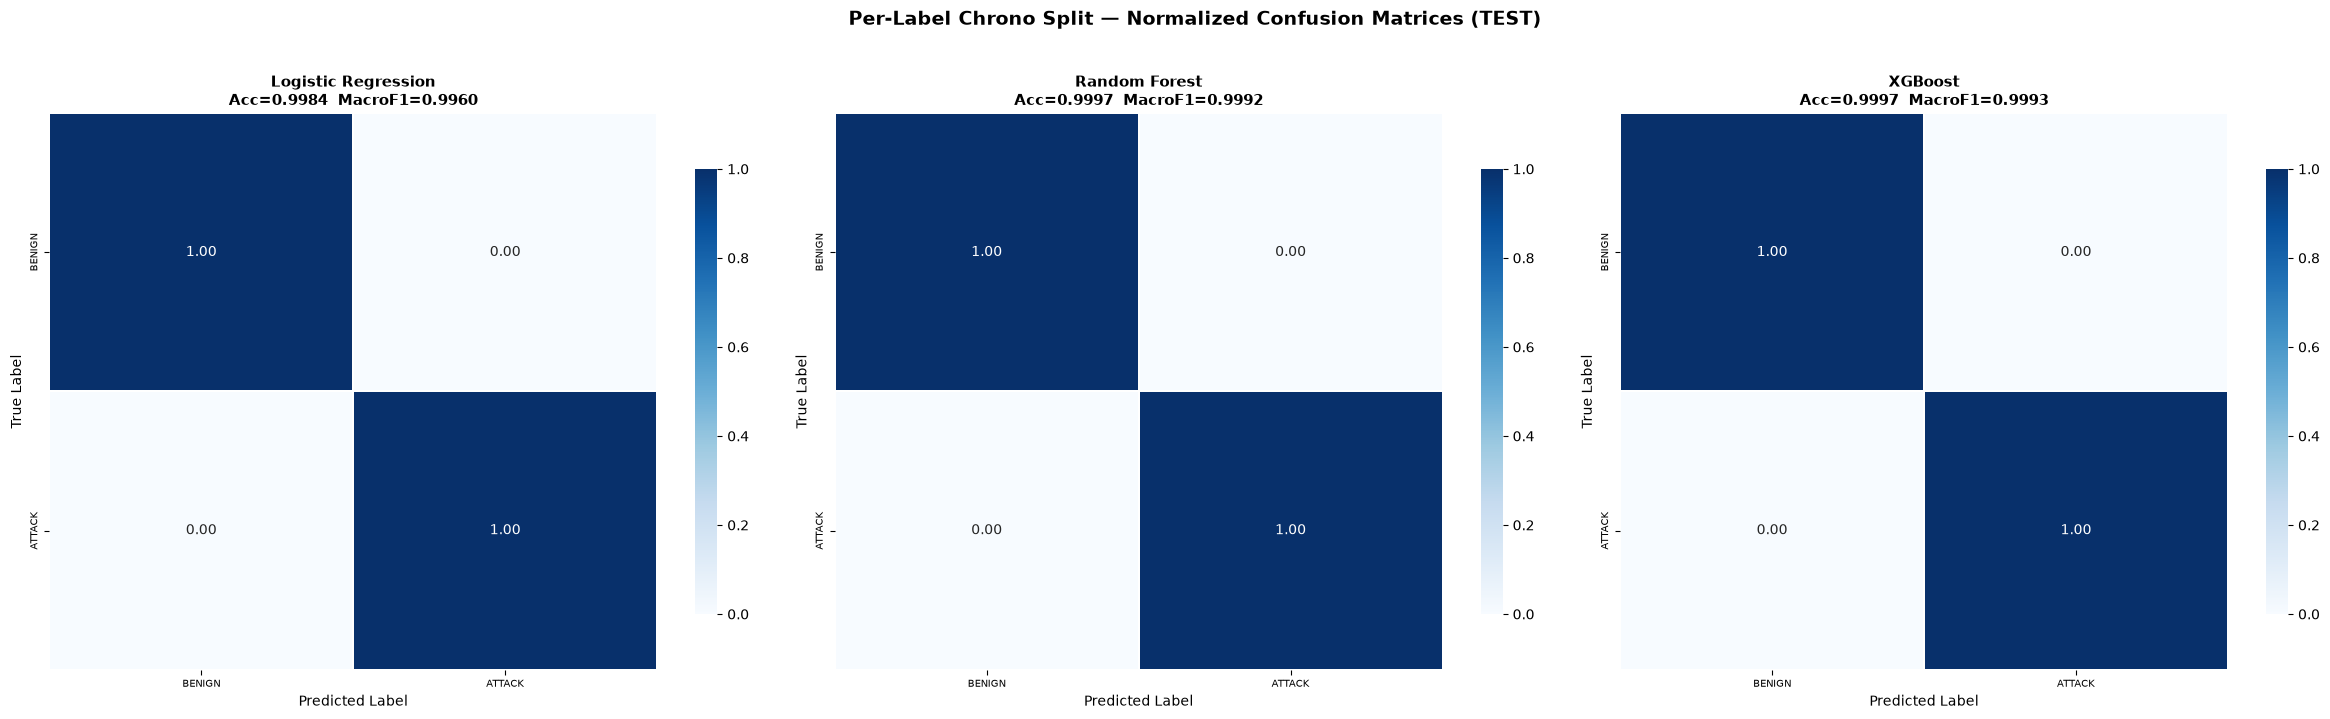

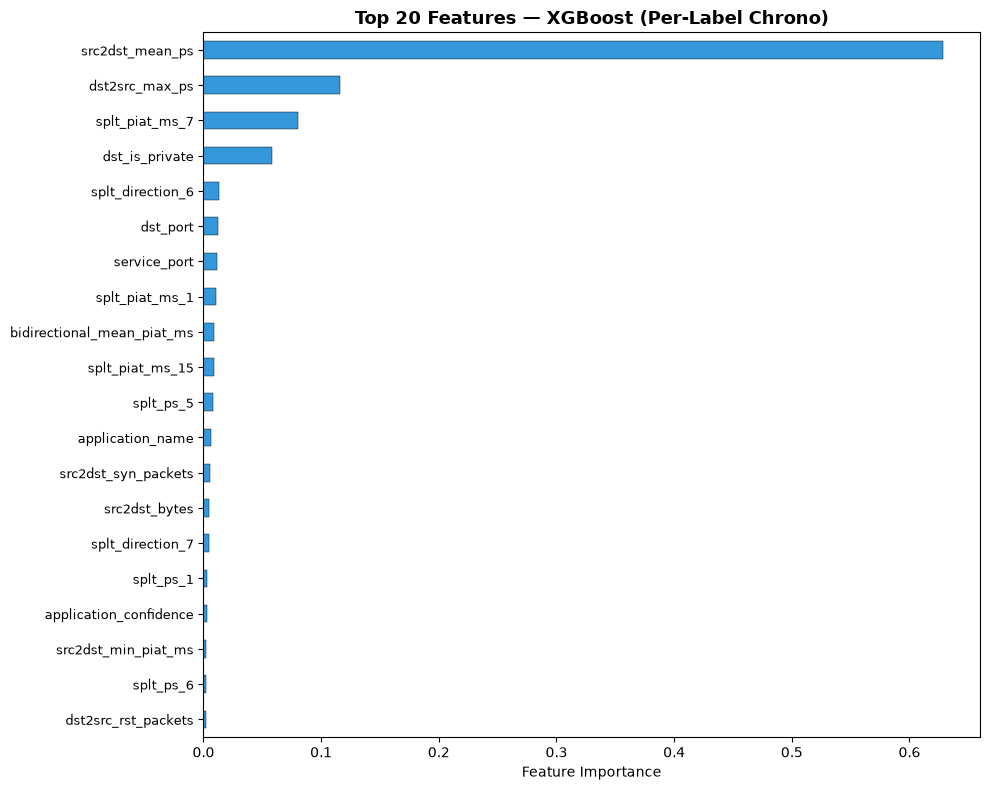

Per-Label Chrono Split — Summary

              Model Device Accuracy Weighted F1 Macro F1 Train Time (s) Val Accuracy Val Macro F1
Logistic Regression    CPU   0.9984      0.9984   0.9960           36.4       0.9987       0.9966
      Random Forest    CPU   0.9997      0.9997   0.9992            5.6       0.9995       0.9986
            XGBoost    GPU   0.9997      0.9997   0.9993            1.3       0.9420       0.8788

XGBoost baseline results saved to prepared_data/xgb_baseline_results.npz


In [22]:
if isinstance(globals().get('ls_results', None), dict) and len(ls_results) > 0:
    show_reports(ls_results, y_test_ls, ls_class_names)
    show_confusion_matrices(ls_results, y_test_ls, ls_class_names, 'Per-Label Chrono Split — Normalized Confusion Matrices (TEST)')
    show_feature_importance(ls_trained_models, active_feature_cols, '(Per-Label Chrono)')
    s14_summary = show_summary(ls_results, ls_class_names, 'Per-Label Chrono Split — Summary')

    # Save XGBoost baseline results for reuse in 03_graph_ml.ipynb
    if 'XGBoost' in ls_results:
        xgb_res = ls_results['XGBoost']
        np.savez(
            prepared_data_dir / 'xgb_baseline_results.npz',
            test_preds=xgb_res['y_pred'],
            test_true=y_test_ls,
            accuracy=np.float64(xgb_res['accuracy']),
            f1_macro=np.float64(xgb_res['f1_macro']),
            f1_weighted=np.float64(xgb_res['f1_weighted']),
            train_time=np.float64(xgb_res['train_time']),
        )
        print(f"\nXGBoost baseline results saved to {prepared_data_dir / 'xgb_baseline_results.npz'}")

---
## Cross-Section Comparison

In [23]:
print("=" * 80)
print("Cross-Section Comparison - XGBoost Test Metrics")
print("=" * 80)

cross_rows = []

all_sections = [
    ('Balanced Binary (Random)', 'bal_results'),
    (f"Cross-Capture ({'+'.join(time_cfg.train_captures)} -> {'+'.join(time_cfg.test_captures)})", 'ts_results'),
    ('Capture-Stratified 70/30', 'ds_results'),
    ('Chronological 70/15/15', 'cs_results'),
    ('Per-Label Chrono 70/15/15', 'ls_results'),
]

for sec_name, results_var in all_sections:
    sec_res = globals().get(results_var, None)
    if isinstance(sec_res, dict) and 'XGBoost' in sec_res:
        m = sec_res['XGBoost']
        cross_rows.append({
            'Section': sec_name,
            'Accuracy': f"{m['accuracy']:.4f}",
            'Macro F1': f"{m['f1_macro']:.4f}",
            'Weighted F1': f"{m['f1_weighted']:.4f}",
        })

if cross_rows:
    cross_df = pd.DataFrame(cross_rows)
    print(cross_df.to_string(index=False))
else:
    print("No sections were run.")

print(f"\nNotebook runtime: {(time.time() - NOTEBOOK_T0) / 60:.1f} min")

Cross-Section Comparison - XGBoost Test Metrics
                  Section Accuracy Macro F1 Weighted F1
 Balanced Binary (Random)   0.9535   0.9534      0.9534
 Cross-Capture (07 -> 10)   0.9995   0.9989      0.9995
 Capture-Stratified 70/30   0.9895   0.9721      0.9893
   Chronological 70/15/15   0.9995   0.9992      0.9995
Per-Label Chrono 70/15/15   0.9997   0.9993      0.9997

Notebook runtime: 12.0 min
